# Taxonomy classification

Reflectance relative to the Sun (normalised to $g$) and spectral gradients from the absolute magnitudes $H_f$.

## 1. Taxonomy: gri slope and i−z from the catalogue colours

Method of **Carruba et al. (2026)**: each object is placed on the plane **gri slope [%/100nm] vs i−z [mag]**
and gets the class of the box (A, B, C, D, L, Q, S, V, X) that contains it.

Here the colours are the catalogue columns `g-r`, `r-i`, `i-z` (and their errors), measured from the light curves.
With $m_r - m_g = -(g-r)$ and $m_i - m_g = -(g-i)$, $g-i = (g-r) + (r-i)$:

$$R_{r,g} = 10^{-0.4\left[-(g-r) - (M_r^{\odot} - M_g^{\odot})\right]}, \qquad
R_{i,g} = 10^{-0.4\left[-(g-i) - (M_i^{\odot} - M_g^{\odot})\right]}$$

$$S = 10^4 \, \frac{R_{r,g} - R_{i,g}}{|\lambda_i - \lambda_r|} \quad [\%/100\,\mathrm{nm}]$$

computed with `tx.reflectance` and `tx.spectral_gradient`, with SDSS effective wavelength:

| | $\lambda_r$ [nm] | $\lambda_i$ [nm] |
|---|---|---|
| SDSS (`tx.LAM_SDSS`) | 614.2 | 745.9 |

And **SDSS Vega** solar magnitudes: 

|band | $M_{\odot}$ | 
|---|---|
| g | -26.34 |
| r | -27.04 | 
| i | -27.38 | 

The vertical axis is the raw $i-z$ colour. The slope error is propagated from the colour errors (`tx.gri_slope_err`).

In [1]:
import os
import matplotlib.pyplot as plt
import taxonomy as tx
import pandas as pd

In [2]:
PAPER = 'data/carruba2026_propiedades.csv'      # Carruba et al. (2026)
FIG_DIR = 'figures/taxonomy_carruba'            # one taxonomy plot per object
OUT_CSV = 'data/taxonomy_classification_carruba.csv'
DATA = 'data/mvroc (1).csv'
os.makedirs(FIG_DIR, exist_ok=True)

carruba_objects = pd.read_csv(PAPER, dtype={'designation': str})
df = pd.read_csv(DATA)

g_i = df['g-r'] + df['r-i']
Rrg = tx.reflectance(-df['g-r'], tx.M_SUN_SDSS['r'], tx.M_SUN_SDSS['g'])
Rig = tx.reflectance(-g_i, tx.M_SUN_SDSS['i'], tx.M_SUN_SDSS['g'])

taxo = df[['provid', 'permid', 'mpc_designation', 'n_obs', 'g-r', 'g-r_err', 'r-i', 'r-i_err',
           'i-z', 'i-z_err']].copy()
taxo['R_rg'] = Rrg
taxo['R_ig'] = Rig
lam_set = tx.LAM_SDSS

taxo[f'slope'] = tx.spectral_gradient_carruba(Rrg, Rig, lam_set['r'], lam_set['i'])
taxo[f'slope_err'] = tx.gri_slope_err_carruba(df['g-r'], df['r-i'], df['g-r_err'], df['r-i_err'], lam=lam_set)

taxo['i_z'] = df['i-z']
taxo['i_z_err'] = df['i-z_err']

has_data = taxo[['slope', 'i_z']].notna().all(axis=1)
print(f'{len(taxo)} objects, {has_data.sum()} with gri slope and i-z')
taxo.loc[has_data, ['provid', 'R_rg', 'R_ig', 'slope', 'slope_err', 'i_z', 'i_z_err']].round(3).head(10)

1092 objects, 134 with gri slope and i-z


,provid,R_rg,R_ig,slope,slope_err,i_z,i_z_err
0,1972 TC2,1.849,0.671,89.414,0.821,0.086,0.011
5,1985 QP5,0.948,0.858,6.821,0.125,0.038,0.003
37,1998 QC2,0.881,0.762,9.003,0.140,-0.035,0.003
38,1998 SB139,0.707,0.560,11.175,0.127,0.138,0.003
51,1999 RM160,0.782,0.609,13.095,0.113,0.056,0.003
52,1999 SB19,0.786,0.660,9.587,0.177,0.027,0.005
53,1999 TD293,0.854,0.790,4.816,0.158,-0.155,0.004
54,1999 TD293,0.975,0.963,0.852,0.224,-0.150,0.004
58,1999 UD26,1.018,0.818,15.209,0.294,-0.337,0.006
62,1999 XJ217,0.747,0.705,3.213,0.528,-0.027,0.019


### 1.1 Classification

Each object gets the probability of every class (`tx.classify_catalogue`): its position is drawn 20 000 times from
its errors (plus systematic floors of 0.25 %/100nm in slope and 0.01 mag in i−z) and each draw votes for the
**region** that contains it.

Several boxes overlap, so the plane is split into regions with exactly one class each (shaded in the diagrams;
`tx.REGION_PRIORITY`):

| overlap | belongs to |
|---|---|
| B inside C | B |
| C/X, D/X | X |
| D/L (i−z 0.080–0.085) | L |
| Q/S, Q/C | Q |
| A/S | A |

* the most likely class with $P \ge 0.60$ → that class;
* no class reaches 0.60 → `indeterminate` (the `candidates` column lists the competing classes);
* most draws fall outside every box → `unclassified`.

The classification is done twice, once with each slope: `taxonomy_lsst` and `taxonomy_sdss`.

In [3]:
taxo

,provid,permid,mpc_designation,n_obs,g-r,g-r_err,r-i,r-i_err,i-z,i-z_err,R_rg,R_ig,slope,slope_err,i_z,i_z_err
0,1972 TC2,4005.0,(4005) Dyagilev,193,1.367378,0.008791,-0.759803,0.008260,0.085745,0.010728,1.849061,0.671475,89.414277,0.821315,0.085745,0.010728
1,1978 UU1,4273.0,(4273) Dunhuang,342,0.616510,0.001852,0.205566,0.001350,NaN,NaN,0.925985,0.818145,8.188271,0.078478,NaN,NaN
2,1978 UU1,4273.0,(4273) Dunhuang,342,0.615983,0.001523,0.186299,0.001618,NaN,NaN,0.925536,0.803365,9.276430,0.091838,NaN,NaN
3,1981 US22,12215.0,(12215) Jessicalounsbury,670,0.642561,0.001157,0.201056,0.001116,NaN,NaN,0.948472,0.834539,8.650889,0.065785,NaN,NaN
4,1981 US22,12215.0,(12215) Jessicalounsbury,670,0.635566,0.001184,0.216538,0.000945,NaN,NaN,0.942380,0.841088,7.691158,0.056191,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1087,2026 DT43,NaN,2026 DT43,574,0.514914,0.003172,0.369574,0.003122,-0.142465,0.002796,0.843268,0.866553,-1.768029,0.189240,-0.142465,0.002796
1088,2026 DT43,NaN,2026 DT43,574,0.631841,0.003729,0.205122,0.003483,0.065800,0.003121,0.939153,0.829441,8.330471,0.204067,0.065800,0.003121
1089,2026 DT43,NaN,2026 DT43,574,0.549214,0.003450,0.278255,0.003457,0.006161,0.003143,0.870333,0.822219,3.653293,0.199143,0.006161,0.003143
1090,2026 DV51,NaN,2026 DV51,580,0.443817,0.003837,0.177894,0.003599,0.019428,0.003620,0.789817,0.680274,8.317600,0.173741,0.019428,0.003620


In [4]:
res = tx.classify_catalogue(taxo[f'slope'], taxo['i_z'], taxo[f'slope_err'], taxo['i_z_err'])
taxo[f'taxonomy'] = res['taxonomy']
taxo[f'p_class'] = res['p_class']
taxo[f'candidates'] = res['candidates']

pd.DataFrame({'SDSS slope': taxo.loc[has_data, 'taxonomy'].value_counts()}).fillna(0).astype(int)

,SDSS slope
taxonomy,
S,36
X,29
D,19
L,19
indeterminate,15
C,7
unclassified,6
B,2
V,1


### 1.2 Distribution of the taxonomies (SDSS slope)

All objects with a slope and i−z, at their SDSS slope, coloured by their class (grey = indeterminate).
Objects `unclassified` (far from every box) are listed in the title but not drawn.

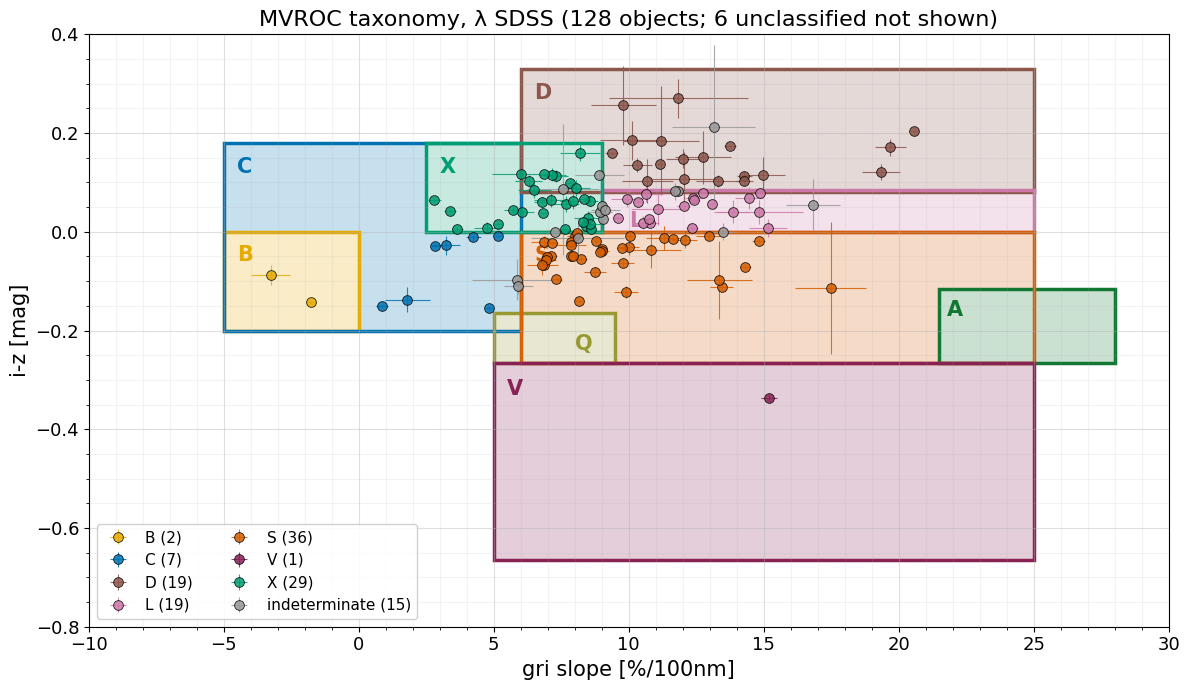

not shown (unclassified): ['1972 TC2', '2007 EW92', '2010 GS195', '2010 RH164', '2010 VZ213', '2013 BM30']


In [5]:
colors = {c: b[4] for c, b in tx.TAXO_BOXES.items()}
colors[tx.INDETERMINATE] = '0.6'

sel = taxo[has_data & (taxo['taxonomy'] != tx.UNCLASSIFIED)]
outsiders = taxo.loc[taxo['taxonomy'] == tx.UNCLASSIFIED, 'provid'].tolist()

fig, ax = plt.subplots(figsize=(12, 7))
tx.plot_taxonomy([], ax=ax, legend=False)
order = sorted(sel['taxonomy'].unique(), key=lambda c: (c == tx.INDETERMINATE, c))
for label in order:
    g = sel[sel['taxonomy'] == label]
    ax.errorbar(g['slope'], g['i_z'], xerr=g['slope_err'], yerr=g['i_z_err'],
                fmt='o', ms=7, color=colors.get(label, 'k'), mec='k', mew=0.6,
                elinewidth=0.8, alpha=0.85, label=f'{label} ({len(g)})', zorder=4)
ax.set_xlim(min(-10, sel['slope'].min() - 3), max(30, sel['slope'].max() + 3))
ax.set_ylim(min(-0.8, sel['i_z'].min() - 0.1), max(0.4, sel['i_z'].max() + 0.1))
ax.set_title(f'MVROC taxonomy, λ SDSS ({len(sel)} objects; {len(outsiders)} unclassified not shown)', fontsize=16)
ax.legend(loc='lower left', fontsize=11, ncol=2, framealpha=0.9)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '_overview_taxonomy.png'), dpi=150)
plt.show()
print('not shown (unclassified):', outsiders)

### 1.3 One diagram per object, all its solutions

Each figure shows one object with every solution of `DATA` at its SDSS slope, one star per solution
(red = sol 1, blue = sol 2, green = sol 3), each with its 1σ error bars. The legend gives the slope,
i−z and class of each solution. Files: `figures/taxonomy_carruba/<provid>_taxonomy.png`.

103 figures (one per object, 134 solutions) saved in figures/taxonomy_carruba/


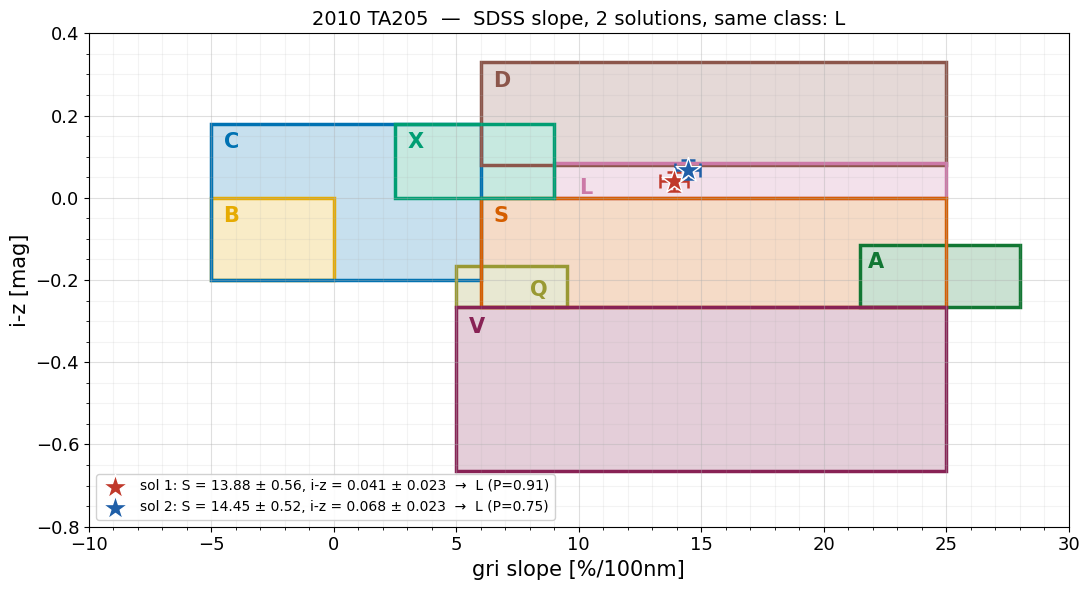

In [6]:
import numpy as np

STAR_COLORS = ['#C0392B', '#1F5FA8', '#117733']   # solution 1 red, 2 blue, 3 green


def class_label(row, name=None):
    # class with its probability; name=None uses the columns without suffix (taxonomy, p_class, candidates)
    sfx = f'_{name}' if name else ''
    t = row[f'taxonomy{sfx}']
    if t == tx.INDETERMINATE:
        return f"indet. ({row[f'candidates{sfx}']})"
    if t in tx.TAXO_BOXES:
        return f"{t} (P={row[f'p_class{sfx}']:.2f})"
    return t


def plot_object_sdss(provid, out_dir=None):
    # one object on the diagram: every solution (SDSS slope and i-z) with its 1-sigma errors
    g = taxo_sol[(taxo_sol['provid'] == provid) & has_data].sort_values('solution_id')
    points = []
    for k, (_, r) in enumerate(g.iterrows()):
        points.append(dict(label=f"sol {r['solution_id']}: S = {r['slope']:.2f} ± {r['slope_err']:.2f}, "
                                 f"i-z = {r['i_z']:.3f} ± {r['i_z_err']:.3f}  →  {class_label(r)}",
                           slope=r['slope'], slope_err=r['slope_err'], iz=r['i_z'], iz_err=r['i_z_err'],
                           color=STAR_COLORS[k % len(STAR_COLORS)]))
    fig, ax = plt.subplots(figsize=(11, 6))
    tx.plot_taxonomy(points, ax=ax, legend=False)
    classes = list(g['taxonomy'])
    status = (f"{len(g)} solutions, same class: {classes[0]}" if len(g) > 1 and len(set(classes)) == 1
              else f"{len(g)} solutions, classes differ" if len(g) > 1 else '1 solution')
    ax.set_title(f"{provid}  —  SDSS slope, {status}", fontsize=14)
    ax.legend(loc='lower left', fontsize=10, framealpha=0.9)
    fig.tight_layout()
    if out_dir is not None:
        fig.savefig(os.path.join(out_dir, f"{provid.replace(' ', '_')}_taxonomy.png"), dpi=120)
    return fig, ax


# DATA has one row per solution: group them by object
taxo_sol = taxo.assign(solution_id=df['solution_id'])
objects = list(dict.fromkeys(taxo_sol.loc[has_data, 'provid']))
for f in os.listdir(FIG_DIR):            # remove the old one-figure-per-solution files
    if '_sol_' in f and f.endswith('_taxonomy.png'):
        os.remove(os.path.join(FIG_DIR, f))
for provid in objects:
    fig, ax = plot_object_sdss(provid, out_dir=FIG_DIR)
    plt.close(fig)
print(f'{len(objects)} figures (one per object, {has_data.sum()} solutions) saved in {FIG_DIR}/')

fig, ax = plot_object_sdss('2010 TA205')
plt.show()

### 1.4 Comparison with Carruba et al. (2026)

`designation` in the paper is a provisional designation (`2010 TA205`) or a number (`3021`); it is matched
against `provid` and, for numbered objects, against `permid`. One row per solution of `DATA`.
The paper gives two light-curve fits (LSM and HOF); `taxonomy_final` is its adopted class.
`agree` compares our class (SDSS slope) with `taxonomy_final`: `yes`, `in candidates` (the paper's class is among
our candidate classes) or `no`.

In [7]:
import numpy as np

key = taxo.assign(number=taxo['permid'].astype('Int64').astype(str), solution_id=df['solution_id'])
paper_cols = ['designation', 'gri_slope_LSM', 'gri_slope_LSM_err', 'i_z_LSM', 'i_z_LSM_err',
              'gri_slope_HOF', 'gri_slope_HOF_err', 'i_z_HOF', 'i_z_HOF_err', 'taxonomy_LSM', 'taxonomy_HOF', 'taxonomy_final']
cmp_paper = (pd.concat([carruba_objects[paper_cols].merge(key, left_on='designation', right_on='provid'),
                        carruba_objects[paper_cols].merge(key[key['permid'].notna()], left_on='designation',
                                                          right_on='number')], ignore_index=True)
               .drop_duplicates(['designation', 'solution_id'])
               .sort_values(['designation', 'solution_id']).reset_index(drop=True))

print(f"{cmp_paper['designation'].nunique()} of {len(carruba_objects)} paper objects found in {DATA}; "
      f"{cmp_paper.dropna(subset=['slope', 'i_z'])['designation'].nunique()} of them have our slope and i-z "
      f"({cmp_paper[['slope', 'i_z']].notna().all(axis=1).sum()} solutions)")


def agree(row, name='lsst'):
    # name=None: columns without suffix (section 4, SDSS); 'lsst' for the later sections
    sfx = f'_{name}' if name else ''
    ours, paper = row[f'taxonomy{sfx}'], row['taxonomy_final']
    if pd.isna(paper) or ours == tx.NO_DATA:
        return '-'
    if ours == paper:
        return 'yes'
    cands = [c.split()[0] for c in str(row[f'candidates{sfx}']).split(' / ') if c]
    return 'in candidates' if paper in cands else 'no'


cmp_paper['agree'] = cmp_paper.apply(agree, axis=1, name=None)
print(cmp_paper['agree'].value_counts().to_string())
cmp_paper[['designation', 'provid', 'solution_id', 'slope', 'slope_err', 'gri_slope_LSM', 'gri_slope_HOF',
           'i_z', 'i_z_LSM', 'taxonomy', 'candidates', 'taxonomy_LSM', 'taxonomy_HOF',
           'taxonomy_final', 'agree']].round(3)

8 of 36 paper objects found in data/mvroc (1).csv; 7 of them have our slope and i-z (11 solutions)
agree
yes              7
in candidates    3
-                1
no               1


,designation,provid,solution_id,slope,slope_err,gri_slope_LSM,gri_slope_HOF,i_z,i_z_LSM,taxonomy,candidates,taxonomy_LSM,taxonomy_HOF,taxonomy_final,agree
0,2010 TA205,2010 TA205,1,13.878,0.563,11.90,11.68,0.041,0.050,L,L 0.91 / S 0.05,L,L,L,yes
1,2010 TA205,2010 TA205,2,14.450,0.519,11.90,11.68,0.068,0.050,L,L 0.75 / D 0.25,L,L,L,yes
2,2014 GO95,2014 GO95,1,9.852,0.357,11.48,11.55,NaN,NaN,no data,,NaN,NaN,NaN,-
3,2015 BE640,2015 BE640,1,7.629,0.146,8.18,8.01,0.005,0.007,X,X 0.69 / S 0.31,X,X,X,yes
4,2015 BE640,2015 BE640,2,8.603,0.147,8.18,8.01,0.005,0.007,X,X 0.62 / S 0.32 / L 0.06,X,X,X,yes
5,2021 JZ24,2021 JZ24,1,9.002,0.139,9.14,9.16,0.051,0.053,indeterminate,X 0.50 / L 0.50,L,L,L,in candidates
6,2021 RW144,2021 RW144,1,9.928,0.585,16.01,12.71,0.067,0.150,L,L 0.75 / D 0.18 / X 0.07,D,D,D,in candidates
7,2021 RW144,2021 RW144,2,11.713,0.499,16.01,12.71,0.082,0.150,indeterminate,L 0.56 / D 0.44,D,D,D,in candidates
8,2021 RW144,2021 RW144,3,19.692,0.579,16.01,12.71,0.171,0.150,D,D 1.00,D,D,D,yes
9,2025 KJ25,2025 KJ25,1,14.322,0.191,12.46,19.40,-0.072,0.050,S,S 1.00,L,L,L,no


### 1.5 Diagram per object: ours vs the paper

One panel per common object with i−z. Each panel shows our SDSS gri slope for every solution (one colour per
solution) and the paper's two light-curve fits, LSM (black) and HOF (grey), each with its 1σ error bars.
The title gives our class for each solution and the paper's classes.

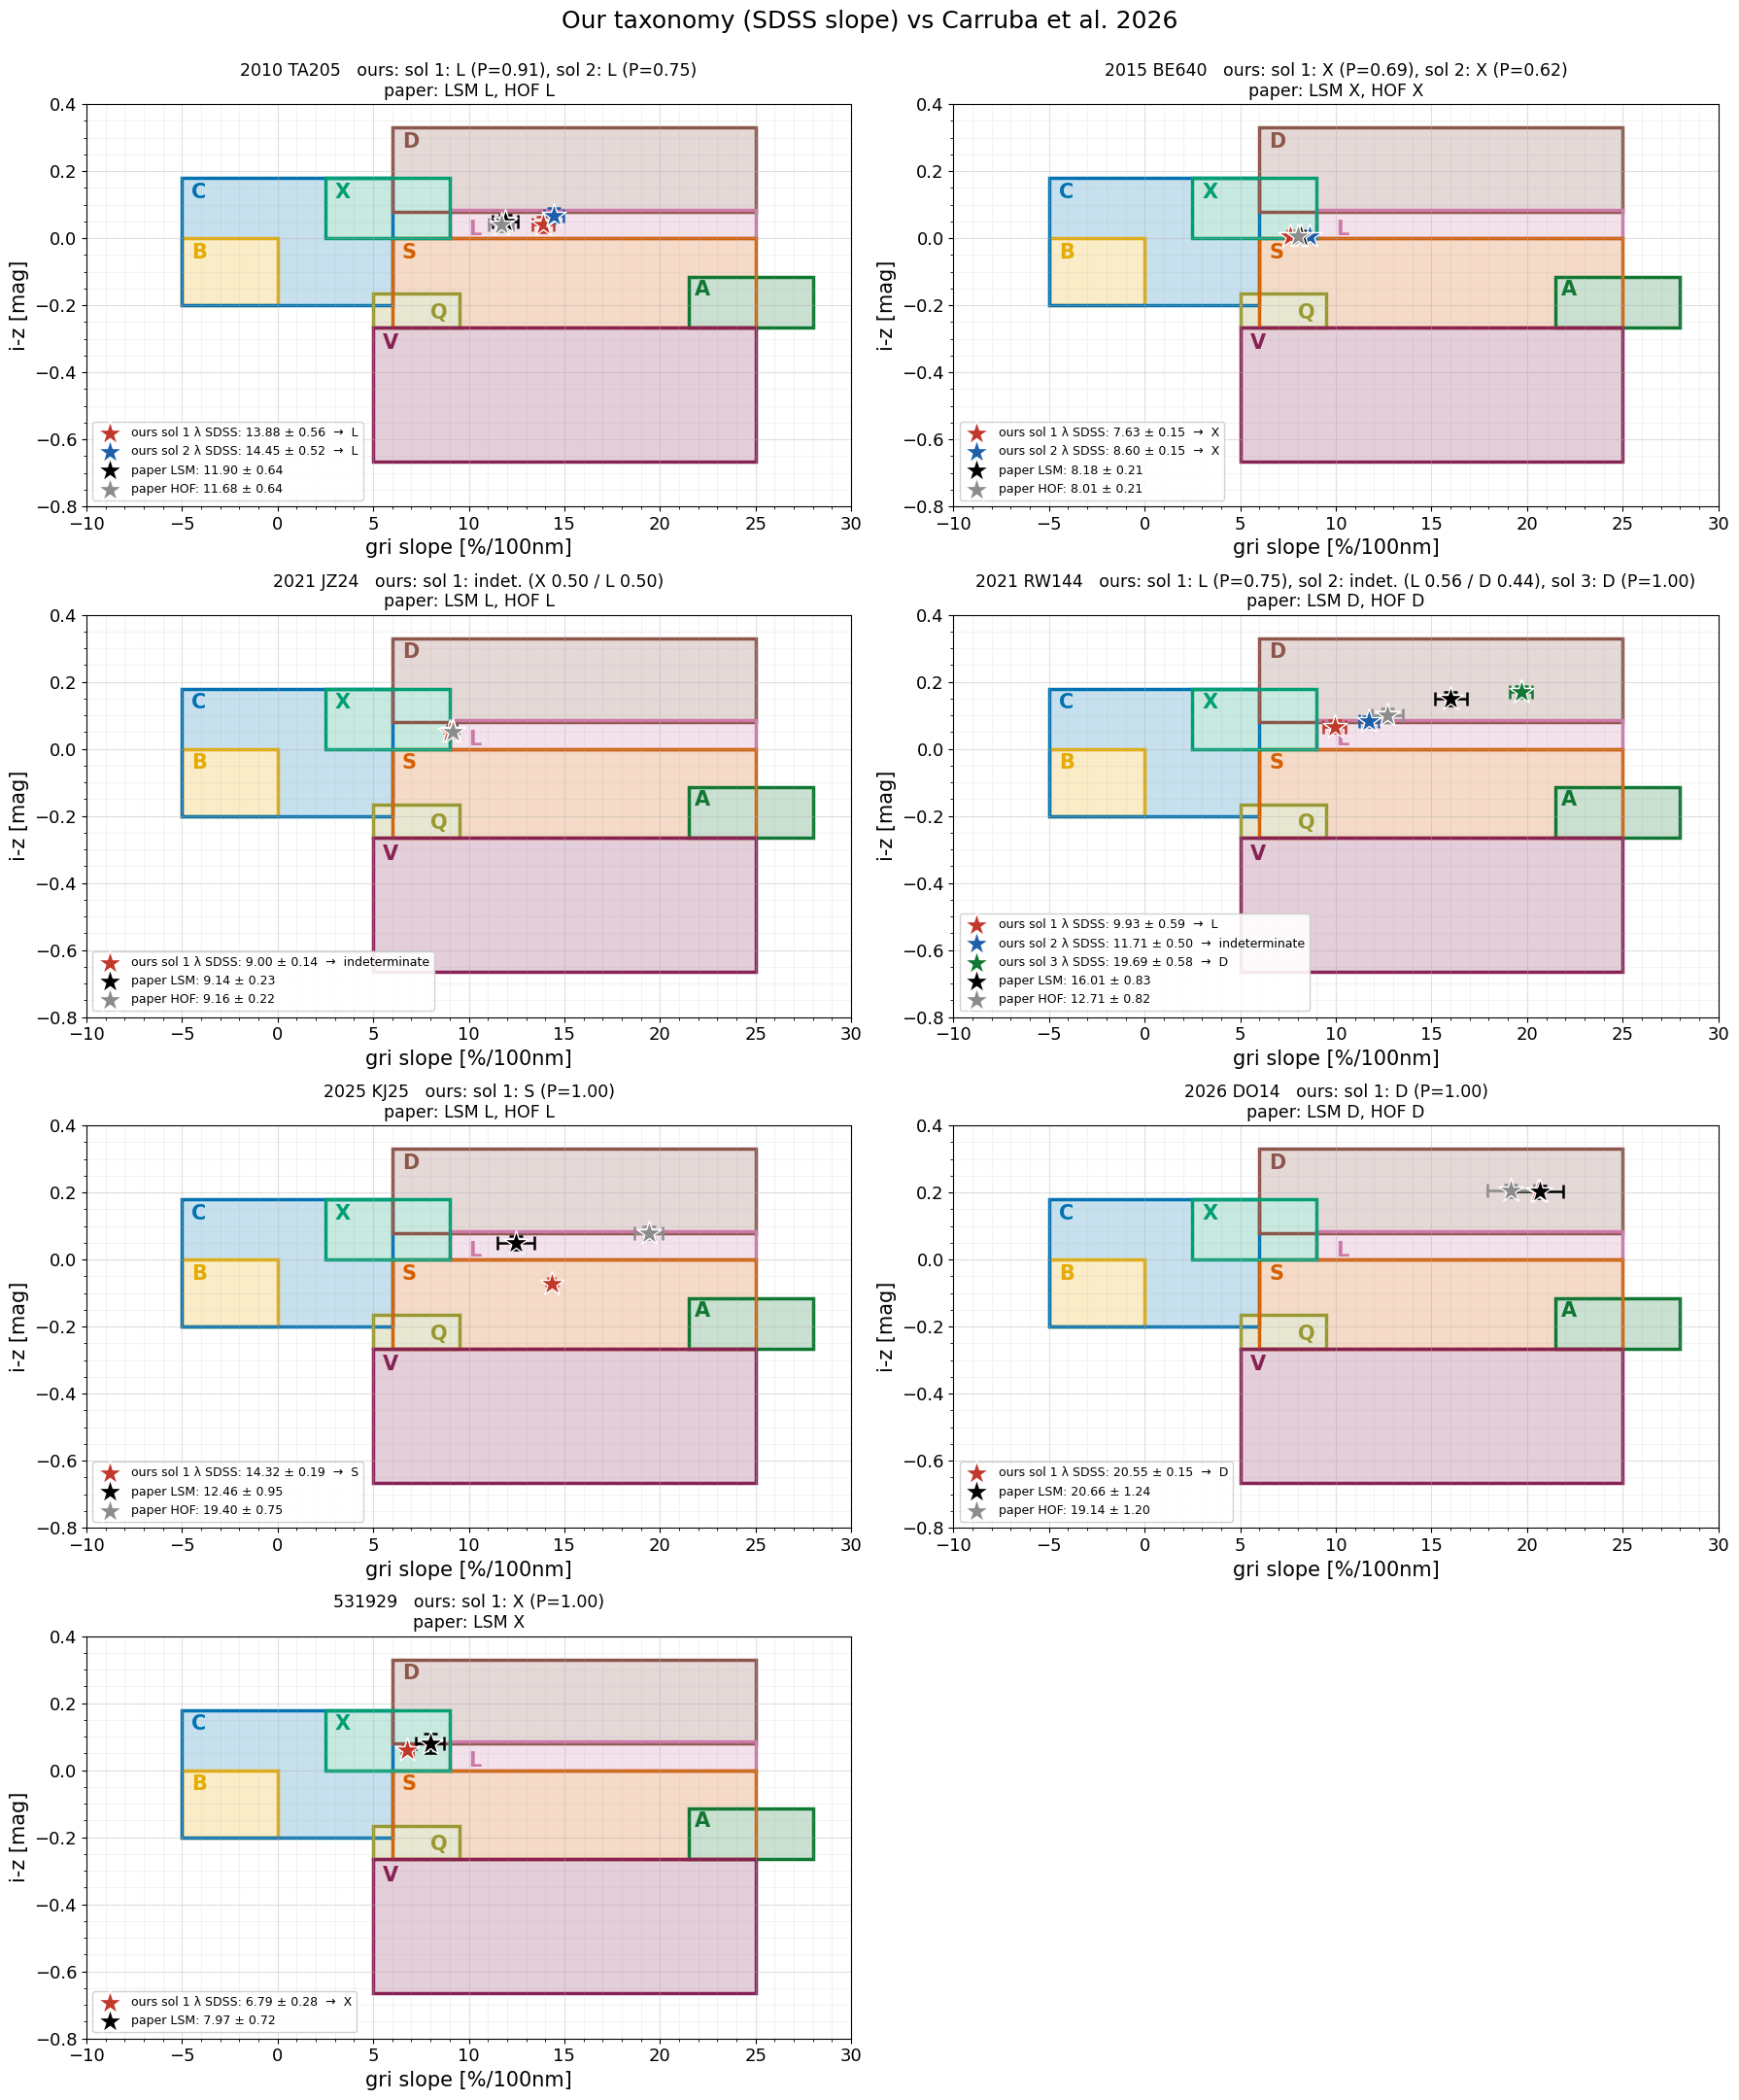

In [8]:
SOL_STARS = ['#C0392B', '#1F5FA8', '#117733']   # solution 1 red, 2 blue, 3 green

both = cmp_paper.dropna(subset=['slope', 'i_z']).reset_index(drop=True)
names_cmp = list(dict.fromkeys(both['designation']))
ncols = 2
nrows = int(np.ceil(len(names_cmp) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5.5 * nrows), squeeze=False)
for ax, name in zip(axes.flat, names_cmp):
    g = both[both['designation'] == name]
    r0 = g.iloc[0]
    points = []
    for k, (_, r) in enumerate(g.iterrows()):
        points.append(dict(label=f"ours sol {r['solution_id']} λ SDSS: {r['slope']:.2f} ± {r['slope_err']:.2f}"
                                 f"  →  {r['taxonomy']}",
                           slope=r['slope'], slope_err=r['slope_err'], iz=r['i_z'], iz_err=r['i_z_err'],
                           color=SOL_STARS[k % len(SOL_STARS)]))
    points.append(dict(label=f"paper LSM: {r0['gri_slope_LSM']:.2f} ± {r0['gri_slope_LSM_err']:.2f}",
                       slope=r0['gri_slope_LSM'], slope_err=r0['gri_slope_LSM_err'],
                       iz=r0['i_z_LSM'], iz_err=r0['i_z_LSM_err'], color='#000000'))
    points.append(dict(label=f"paper HOF: {r0['gri_slope_HOF']:.2f} ± {r0['gri_slope_HOF_err']:.2f}",
                       slope=r0['gri_slope_HOF'], slope_err=r0['gri_slope_HOF_err'],
                       iz=r0['i_z_HOF'], iz_err=r0['i_z_HOF_err'], color='#8c8c8c'))
    points = [p for p in points if np.isfinite(p['slope']) and np.isfinite(p['iz'])]
    tx.plot_taxonomy(points, ax=ax)
    ours_lbl = ', '.join(f"sol {r['solution_id']}: {class_label(r)}" for _, r in g.iterrows())
    paper_lbl = f"LSM {r0['taxonomy_LSM']}" + (f", HOF {r0['taxonomy_HOF']}" if pd.notna(r0['taxonomy_HOF']) else '')
    ax.set_title(f"{name}   ours: {ours_lbl}\npaper: {paper_lbl}", fontsize=12.5)
    ax.legend(loc='lower left', fontsize=9, framealpha=0.9)
for ax in axes.flat[len(names_cmp):]:
    ax.axis('off')
fig.suptitle('Our taxonomy (SDSS slope) vs Carruba et al. 2026', fontsize=18)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(os.path.join(FIG_DIR, '_carruba_comparison.png'), dpi=150)
plt.show()

### 1.6 Save the classification table

In [9]:
taxo.to_csv(OUT_CSV, index=False)
print(f'saved {OUT_CSV}  ({len(taxo)} rows)')

saved data/taxonomy_classification_carruba.csv  (1092 rows)


## 2. `mvroc`: weighted linear fit of the reflectances (LSST parameters)

`mvroc (1).csv` has **one row per solution** (`provid` + `solution_id`). For every solution with g−r, r−i and i−z:

1. **Reflectances** with the LSST AB solar magnitudes (`tx.M_SUN_LSST`), normalised to g:
   $R_g = 1$, $R_r = 10^{-0.4[-(g-r) - (M_{r,\odot}-M_{g,\odot})]}$, $R_i = 10^{-0.4[-(g-i) - (M_{i,\odot}-M_{g,\odot})]}$.
2. **Reflectance errors** by error propagation, $\sigma_{R_f} = 0.4\ln 10\, R_f\, \sigma_f$ (`tx.gri_reflectances`).
   The catalogue only gives colour errors, so the error of each band is taken from them assuming each colour
   variance is shared equally by its two bands (a band in two colours takes the mean):
   $\sigma_g^2 = \sigma_{g-r}^2/2$, $\sigma_r^2 = (\sigma_{g-r}^2 + \sigma_{r-i}^2)/4$,
   $\sigma_i^2 = (\sigma_{r-i}^2 + \sigma_{i-z}^2)/4$.
3. **Fit** $R(\lambda) = a + b\lambda$ at the LSST wavelengths with `scipy.optimize.curve_fit` (`tx.gri_slope_fit`),
   `sigma` = reflectance errors, `absolute_sigma=True`, wavelengths exact. gri slope $= 10^4 b$ [%/100nm];
   slope and intercept errors from the fit covariance; $\chi^2$ with 3 − 2 = 1 degree of freedom.
4. **Class** from the slope and i−z with their errors (`tx.classify_catalogue`).

An object is **consistent** when all its solutions get the same class (a box letter); only those are drawn in
the overview. Figures and tables go to `figures/taxonomy_mvroc_curvefit_lsst/`.

In [10]:
import numpy as np

MVROC = 'data/mvroc (1).csv'
FIG_DIR_MV_CF = 'figures/taxonomy_mvroc'
os.makedirs(FIG_DIR_MV_CF, exist_ok=True)
mv = pd.read_csv(MVROC)


def band_errors_from_colors(s):
    # per-band magnitude errors from the colour errors (each colour variance shared equally by its two bands)
    v_gr, v_ri, v_iz = s['g-r_err'] ** 2, s['r-i_err'] ** 2, s['i-z_err'] ** 2
    return np.sqrt(v_gr / 2), np.sqrt((v_gr + v_ri) / 4), np.sqrt((v_ri + v_iz) / 4)


def mvroc_taxonomy(mv_df, m_sun, method='curvefit', lam_sets=('lsst',)):
    # slope, i-z and class of every solution with g-r, r-i and i-z
    #   method='curvefit': weighted fit with tx.gri_slope_fit (LSST wavelengths), reflectance errors and chi2
    #   method='fit'     : unweighted fit from the colours (tx.gri_slope_fit_colors)
    #   method='diff'    : Carruba formula S = 1e4 (R_r - R_i) / |lam_i - lam_r|
    s = mv_df[mv_df[['g-r', 'r-i', 'i-z']].notna().all(axis=1)].copy().reset_index(drop=True)
    s['i_z'] = s['i-z']
    s['i_z_err'] = s['i-z_err']
    if method == 'curvefit':
        lam_sets = ('lsst',)
        s['sigma_g'], s['sigma_r'], s['sigma_i'] = band_errors_from_colors(s)
        R = tx.gri_reflectances(0 * s['g-r'], -s['g-r'], -(s['g-r'] + s['r-i']),
                                s['sigma_g'], s['sigma_r'], s['sigma_i'], m_sun=m_sun)
        s = pd.concat([s, R], axis=1)
        fit = tx.gri_slope_fit(R[['R_g', 'R_r', 'R_i']], R[['R_g_err', 'R_r_err', 'R_i_err']], lam=tx.LAM_LSST)
        s['slope_lsst'] = fit['slope']
        s['slope_lsst_err'] = fit['slope_err']
        for col in ['intercept', 'intercept_err', 'cov_ab', 'chi2', 'ndof', 'p_value']:
            s[col] = fit[col]
    else:
        s['R_rg'] = tx.reflectance(-s['g-r'], m_sun['r'], m_sun['g'])
        s['R_ig'] = tx.reflectance(-(s['g-r'] + s['r-i']), m_sun['i'], m_sun['g'])
        lams = {'lsst': tx.LAM_LSST, 'sdss': tx.LAM_SDSS}
        for name in lam_sets:
            lam_set = lams[name]
            if method == 'fit':
                s[f'slope_{name}'] = tx.gri_slope_fit_colors(s['g-r'], s['r-i'], lam=lam_set, m_sun=m_sun)
                s[f'slope_{name}_err'] = tx.gri_slope_fit_colors_err(s['g-r'], s['r-i'], s['g-r_err'], s['r-i_err'],
                                                                     lam=lam_set, m_sun=m_sun)
            else:
                s[f'slope_{name}'] = tx.spectral_gradient_carruba(s['R_rg'], s['R_ig'], lam_set['r'], lam_set['i'])
                s[f'slope_{name}_err'] = tx.gri_slope_err_carruba(s['g-r'], s['r-i'], s['g-r_err'], s['r-i_err'],
                                                                  lam=lam_set, m_sun=m_sun)
    for name in lam_sets:
        res = tx.classify_catalogue(s[f'slope_{name}'], s['i_z'], s[f'slope_{name}_err'], s['i_z_err'])
        s[f'taxonomy_{name}'] = res['taxonomy']
        s[f'p_class_{name}'] = res['p_class']
        s[f'candidates_{name}'] = res['candidates']
    return s


def summarise(g):
    # one row per object: classes of its solutions and whether they all agree
    classes = list(g['taxonomy_lsst'])
    same = len(set(classes)) == 1 and classes[0] in tx.TAXO_BOXES
    return pd.Series({
        'n_solutions': len(g),
        'classes_lsst': ' / '.join(f'{s}:{c}' for s, c in zip(g['solution_id'], classes)),
        'consistent': same,
        'taxonomy': classes[0] if same else ('indeterminate' if set(classes) == {tx.INDETERMINATE} else 'mixed'),
        'slope_lsst_range': g['slope_lsst'].max() - g['slope_lsst'].min(),
        'i_z_range': g['i_z'].max() - g['i_z'].min(),
    })


SOL_COLORS = ['#C0392B', '#1F5FA8', '#117733']   # solution 1 red, 2 blue, 3 green
SOL_PAIRS = [('#d62728', '#ff9896'), ('#2ca02c', '#98df8a'), ('#9467bd', '#c5b0d5'), ('#8c564b', '#c49c94')]


def plot_solutions(provid, out_dir=None, sol_df=None, objs_df=None):
    # one object, all its solutions, 2 rows x 1 column:
    #   top   : taxonomy diagram (LSST slope vs i-z) with 1-sigma error bars
    #   bottom: reflectances R_g, R_r, R_i vs LSST wavelength with errors and the weighted linear fit of each solution
    g = sol_df[sol_df['provid'] == provid].sort_values('solution_id')
    o = objs_df.set_index('provid').loc[provid]
    has_fit = all(c in g for c in ['R_g', 'R_g_err', 'intercept', 'chi2'])
    fig, (ax, axf) = plt.subplots(2, 1, figsize=(12, 13))

    # top: taxonomy
    points = []
    for k, (_, r) in enumerate(g.iterrows()):
        cls = r['taxonomy_lsst'] if r['taxonomy_lsst'] != tx.INDETERMINATE else f"indet. ({r['candidates_lsst']})"
        points.append(dict(label=f"sol {r['solution_id']}: S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f},"
                                 f" i-z = {r['i_z']:.3f} ± {r['i_z_err']:.3f}  →  {cls}",
                           slope=r['slope_lsst'], slope_err=r['slope_lsst_err'],
                           iz=r['i_z'], iz_err=r['i_z_err'], color=SOL_COLORS[k % len(SOL_COLORS)]))
    tx.plot_taxonomy(points, ax=ax, legend=False)
    ax.legend(loc='lower left', fontsize=9.5, framealpha=0.9)
    ax.set_title('taxonomy (LSST slope, 1σ error bars)', fontsize=13)

    # bottom: reflectances and the fit of each solution
    if has_fit:
        lam = np.array([tx.LAM_LSST[b] for b in 'gri'])
        lam_line = np.linspace(lam.min() - 25, lam.max() + 25, 50)
        n = len(g)
        for k, (_, r) in enumerate(g.iterrows()):
            c = SOL_COLORS[k % len(SOL_COLORS)]
            dx = (k - (n - 1) / 2) * 4.0          # small shift so the error bars of the solutions do not overlap
            R = np.array([r[f'R_{b}'] for b in 'gri'])
            E = np.array([r[f'R_{b}_err'] for b in 'gri'])
            axf.errorbar(lam + dx, R, yerr=E, fmt='o', ms=7, color=c, mec='k', mew=0.6,
                         elinewidth=1.5, capsize=4, zorder=5)
            if np.isfinite(r['slope_lsst']):
                axf.plot(lam_line, r['intercept'] + r['slope_lsst'] / 1e4 * lam_line, '-', color=c, lw=1.8,
                         label=f"sol {r['solution_id']}: S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f}"
                               f" %/100nm,  χ² = {r['chi2']:.2f} ({int(r['ndof'])} dof), p = {r['p_value']:.2g}")
        for b, l in zip('gri', lam):
            axf.axvline(l, color='0.85', lw=0.8, zorder=0)
            axf.text(l, 0.02, b, transform=axf.get_xaxis_transform(), ha='center', fontsize=12, color='0.4')
        axf.set_xlabel('wavelength [nm] (LSST)', fontsize=14)
        axf.set_ylabel('reflectance (normalised to g)', fontsize=14)
        axf.tick_params(labelsize=12)
        axf.grid(alpha=0.3)
        axf.legend(loc='upper left', fontsize=9.5, framealpha=0.9)
        axf.set_title('weighted linear fit R(λ) = a + bλ (curve_fit)', fontsize=13)
    else:
        axf.axis('off')

    status = f"same class in all {len(g)} solutions: {o['taxonomy']}" if o['consistent'] and len(g) > 1 \
        else (f"1 solution: {o['taxonomy']}" if len(g) == 1 else f"classes differ ({o['classes_lsst']})")
    fig.suptitle(f'{provid}  —  {status}', fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    if out_dir is not None:
        fig.savefig(os.path.join(out_dir, f"{provid.replace(' ', '_')}_solutions.png"), dpi=120)
    return fig, (ax, axf)


sol_cf = mvroc_taxonomy(mv, tx.M_SUN_LSST, method='curvefit')
objs_cf = sol_cf.groupby('provid').apply(summarise, include_groups=False).reset_index()
objs_cf = objs_cf.sort_values(['consistent', 'n_solutions', 'provid'], ascending=[False, False, True])
multi_cf = objs_cf[objs_cf['n_solutions'] > 1]

print(f'{len(mv)} solutions of {mv["provid"].nunique()} objects in {MVROC}')
print(f'with g-r, r-i and i-z: {len(sol_cf)} solutions of {len(objs_cf)} objects')
print(f'  consistent (same class, all solutions) : {objs_cf["consistent"].sum()}'
      f'  ({multi_cf["consistent"].sum()} of {len(multi_cf)} with more than one solution)')
print(f'  not consistent                         : {(~objs_cf["consistent"]).sum()}')
print(f"chi2 (1 dof): median {sol_cf['chi2'].median():.2f}; chi2 > 3.84 (p < 0.05): "
      f"{(sol_cf['chi2'] > 3.84).mean():.0%} of the solutions")
print('\nclasses (all solutions):')
print(sol_cf['taxonomy_lsst'].value_counts().to_string())

fit_cols_mv = ['provid', 'solution_id', 'g-r', 'g-r_err', 'r-i', 'r-i_err', 'sigma_g', 'sigma_r', 'sigma_i',
               'R_g', 'R_g_err', 'R_r', 'R_r_err', 'R_i', 'R_i_err',
               'slope_lsst', 'slope_lsst_err', 'intercept', 'intercept_err', 'cov_ab', 'chi2', 'ndof', 'p_value',
               'i_z', 'i_z_err', 'taxonomy_lsst', 'p_class_lsst', 'candidates_lsst']
mv_fit_params = sol_cf[fit_cols_mv]
mv_fit_params.to_csv(os.path.join(FIG_DIR_MV_CF, 'fit_parameters_mvroc.csv'), index=False)
sol_cf.to_csv(os.path.join(FIG_DIR_MV_CF, 'taxonomy_mvroc_solutions.csv'), index=False)
objs_cf.to_csv(os.path.join(FIG_DIR_MV_CF, 'taxonomy_mvroc_objects.csv'), index=False)
print(f'\ntables saved in {FIG_DIR_MV_CF}/')
mv_fit_params.head(10).round(4)

1092 solutions of 703 objects in data/mvroc (1).csv
with g-r, r-i and i-z: 134 solutions of 103 objects
  consistent (same class, all solutions) : 78  (11 of 25 with more than one solution)
  not consistent                         : 25
chi2 (1 dof): median 30.65; chi2 > 3.84 (p < 0.05): 78% of the solutions

classes (all solutions):
taxonomy_lsst
S                29
C                26
X                23
L                18
indeterminate    16
D                10
unclassified      7
B                 4
V                 1

tables saved in figures/taxonomy_mvroc/


,provid,solution_id,g-r,g-r_err,r-i,r-i_err,sigma_g,sigma_r,sigma_i,R_g,...,intercept,intercept_err,cov_ab,chi2,ndof,i_z,i_z_err,taxonomy_lsst,p_class_lsst,candidates_lsst
0,1972 TC2,1,1.3674,0.0088,-0.7598,0.0083,0.0062,0.0060,0.0068,1.0,...,0.8949,0.0196,-0.0061,9502.3235,1,0.0857,0.0107,X,1.0000,X 1.00
1,1985 QP5,1,0.6424,0.0015,0.2320,0.0021,0.0011,0.0013,0.0017,1.0,...,0.3139,0.0044,-0.0003,611.6510,1,0.0384,0.0026,L,0.9998,L 1.00
2,1998 QC2,1,0.5619,0.0032,0.1830,0.0026,0.0023,0.0021,0.0019,1.0,...,0.6273,0.0069,-0.0007,202.0289,1,-0.0346,0.0028,S,0.9994,S 1.00
3,1998 SB139,1,0.3236,0.0049,0.0866,0.0030,0.0035,0.0029,0.0022,1.0,...,1.1567,0.0087,-0.0011,56.6103,1,0.1379,0.0034,C,0.9999,C 1.00
4,1999 RM160,1,0.4324,0.0028,0.0693,0.0025,0.0020,0.0019,0.0020,1.0,...,1.0568,0.0058,-0.0005,243.4482,1,0.0559,0.0030,C,1.0000,C 1.00
5,1999 SB19,1,0.4383,0.0033,0.1498,0.0038,0.0023,0.0025,0.0029,1.0,...,0.9043,0.0077,-0.0010,0.3884,1,0.0274,0.0045,C,0.9682,C 0.97
6,1999 TD293,1,0.5281,0.0022,0.2562,0.0029,0.0015,0.0018,0.0023,1.0,...,0.5532,0.0059,-0.0006,73.0535,1,-0.1546,0.0037,S,0.8572,S 0.86 / Q 0.14
7,1999 TD293,2,0.6721,0.0020,0.3274,0.0033,0.0014,0.0019,0.0024,1.0,...,0.0598,0.0064,-0.0007,2.8417,1,-0.1498,0.0035,S,1.0000,S 1.00
8,1999 UD26,1,0.7198,0.0025,0.1022,0.0051,0.0018,0.0028,0.0040,1.0,...,0.3025,0.0087,-0.0014,1551.5059,1,-0.3375,0.0062,V,1.0000,V 1.00
9,1999 XJ217,1,0.3839,0.0100,0.2767,0.0107,0.0071,0.0073,0.0111,1.0,...,0.8404,0.0261,-0.0114,90.5420,1,-0.0275,0.0195,C,0.9178,C 0.92 / X 0.08


### 2.1 Overview: objects with the same class in every solution

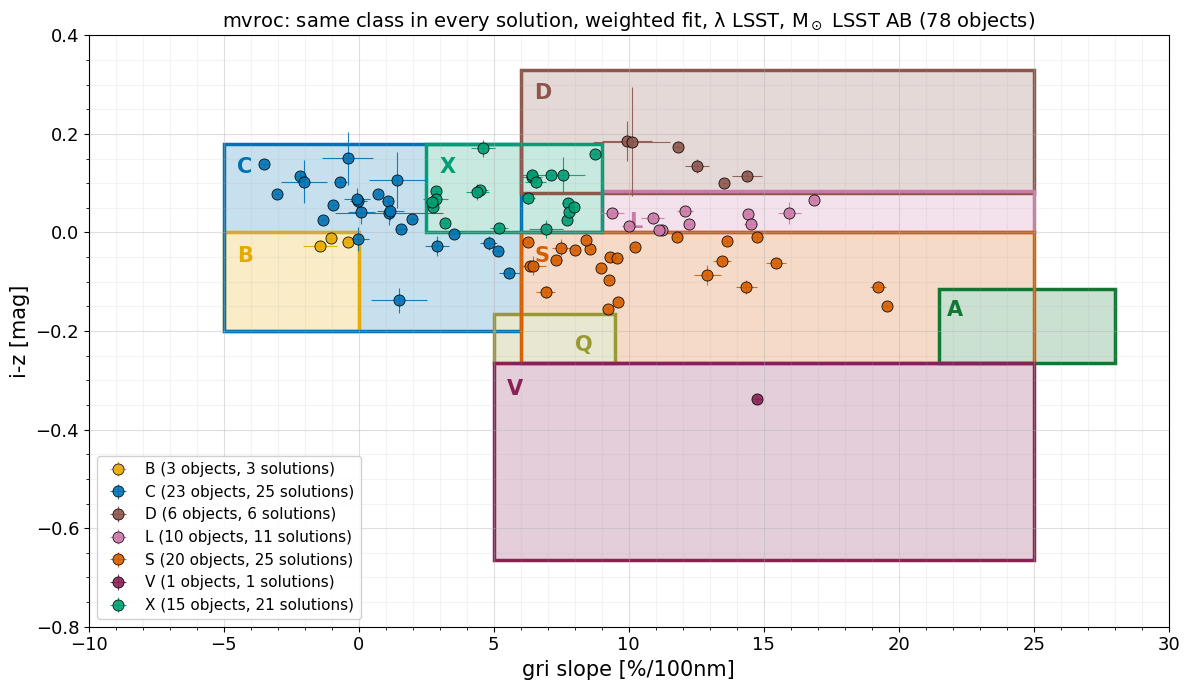

7 objects have at least one solution outside every box (unclassified)


In [11]:
cons_ids_cf = objs_cf.loc[objs_cf['consistent'], 'provid']
cons_cf = sol_cf[sol_cf['provid'].isin(cons_ids_cf)]
outside_cf = sorted(sol_cf.loc[sol_cf['taxonomy_lsst'] == tx.UNCLASSIFIED, 'provid'].unique())

fig, ax = plt.subplots(figsize=(12, 7))
tx.plot_taxonomy([], ax=ax, legend=False)
for label in sorted(cons_cf['taxonomy_lsst'].unique()):
    g = cons_cf[cons_cf['taxonomy_lsst'] == label]
    ax.errorbar(g['slope_lsst'], g['i_z'], xerr=g['slope_lsst_err'], yerr=g['i_z_err'],
                fmt='o', ms=8, color=colors[label], mec='k', mew=0.6, elinewidth=0.8, alpha=0.9,
                label=f"{label} ({g['provid'].nunique()} objects, {len(g)} solutions)", zorder=4)
ax.set_title(f'mvroc: same class in every solution, weighted fit, λ LSST, M$_\\odot$ LSST AB '
             f'({len(cons_ids_cf)} objects)', fontsize=14)
ax.legend(loc='lower left', fontsize=11, framealpha=0.9)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR_MV_CF, '_overview_taxonomy_consistent.png'), dpi=150)
plt.show()
print(f'{len(outside_cf)} objects have at least one solution outside every box (unclassified)')

### 2.2 One figure per object, all its solutions

Top: taxonomy diagram with the LSST slope and i−z of each solution and their 1σ error bars; the legend gives
slope, i−z and class. Bottom: reflectances $R_g, R_r, R_i$ with their errors at the LSST wavelengths and the weighted
linear fit of each solution (one colour per solution, points shifted slightly in λ so they do not overlap);
the legend gives the slope and the χ² of the fit.
Files: `<FIG_DIR_MV_CF>/<provid>_solutions.png`.

103 figures saved in figures/taxonomy_mvroc/


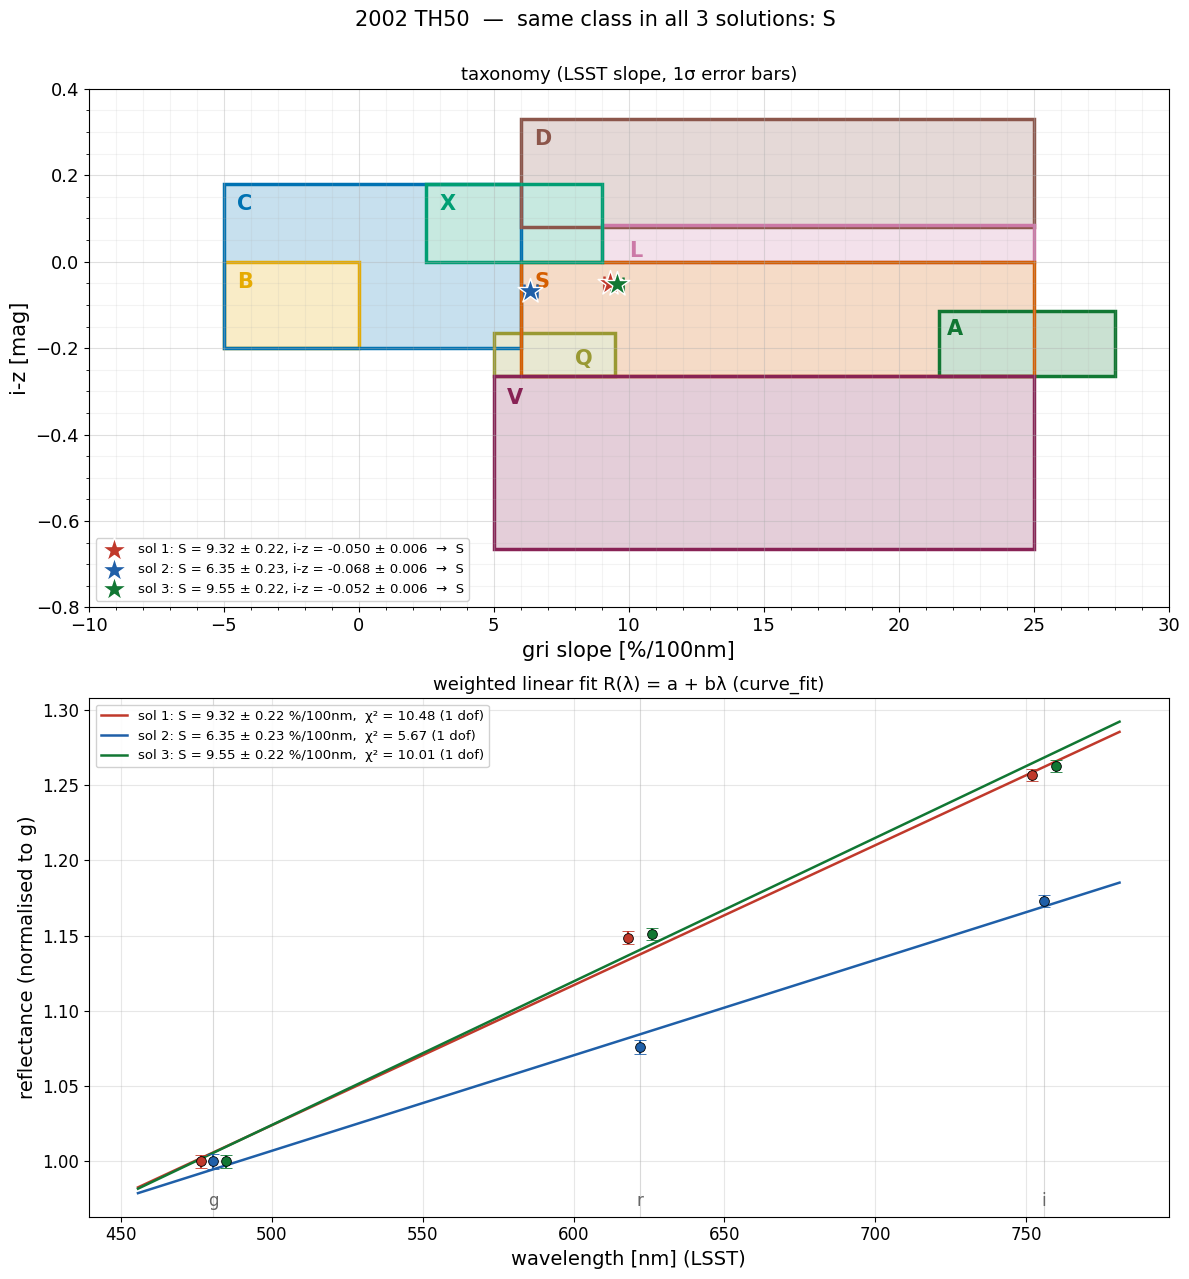

In [12]:
for provid in objs_cf['provid']:
    fig, axes = plot_solutions(provid, out_dir=FIG_DIR_MV_CF, sol_df=sol_cf, objs_df=objs_cf)
    plt.close(fig)
print(f'{len(objs_cf)} figures saved in {FIG_DIR_MV_CF}/')

example = multi_cf['provid'].iloc[0] if len(multi_cf) else objs_cf['provid'].iloc[0]
fig, axes = plot_solutions(example, sol_df=sol_cf, objs_df=objs_cf)
plt.show()

### 2.3 Comparison with Carruba et al. (2026)

Cross-match of the solutions with the paper: `designation` against `provid` and, for numbered objects, against
`permid`. `agree` compares each solution's class with the paper's `taxonomy_final`.

In [13]:
mv_key_cf = sol_cf.assign(number=sol_cf['permid'].astype('Int64').astype(str))
mv_paper_cf = pd.concat([
    carruba_objects[paper_cols].merge(mv_key_cf, left_on='designation', right_on='provid'),
    carruba_objects[paper_cols].merge(mv_key_cf[mv_key_cf['permid'].notna()], left_on='designation',
                                      right_on='number'),
], ignore_index=True).drop_duplicates(['designation', 'solution_id']).sort_values(['designation', 'solution_id'])
mv_paper_cf = mv_paper_cf.reset_index(drop=True)
mv_paper_cf['agree'] = mv_paper_cf.apply(agree, axis=1)

mv_all = mv.assign(number=mv['permid'].astype('Int64').astype(str))
in_mv = carruba_objects['designation'].isin(set(mv_all['provid']) | set(mv_all['number']))
print(f'{in_mv.sum()} of {len(carruba_objects)} paper objects are in {MVROC}; '
      f'{mv_paper_cf["designation"].nunique()} of them have i-z ({len(mv_paper_cf)} solutions)')
print(mv_paper_cf['agree'].value_counts().to_string())
mv_paper_cf.to_csv(os.path.join(FIG_DIR_MV_CF, 'carruba_comparison_mvroc.csv'), index=False)
mv_paper_cf[['designation', 'solution_id', 'slope_lsst', 'slope_lsst_err', 'chi2', 'gri_slope_LSM', 'gri_slope_HOF',
             'i_z', 'i_z_LSM', 'taxonomy_lsst', 'candidates_lsst',
             'taxonomy_LSM', 'taxonomy_HOF', 'taxonomy_final', 'agree']].round(3)

8 of 36 paper objects are in data/mvroc (1).csv; 7 of them have i-z (11 solutions)
agree
no     10
yes     1


,designation,solution_id,slope_lsst,slope_lsst_err,chi2,gri_slope_LSM,gri_slope_HOF,i_z,i_z_LSM,taxonomy_lsst,candidates_lsst,taxonomy_LSM,taxonomy_HOF,taxonomy_final,agree
0,2010 TA205,1,0.084,0.498,21.001,11.90,11.68,0.041,0.050,C,C 0.98,L,L,L,no
1,2010 TA205,2,-0.079,0.489,30.036,11.90,11.68,0.068,0.050,C,C 1.00,L,L,L,no
2,2015 BE640,1,11.219,0.129,174.277,8.18,8.01,0.005,0.007,L,L 0.69 / S 0.31,X,X,X,no
3,2015 BE640,2,11.127,0.131,322.449,8.18,8.01,0.005,0.007,L,L 0.68 / S 0.32,X,X,X,no
4,2021 JZ24,1,7.973,0.129,153.777,9.14,9.16,0.051,0.053,X,X 1.00,L,L,L,no
5,2021 RW144,1,2.847,0.461,0.954,16.01,12.71,0.067,0.150,X,X 0.75 / C 0.25,D,D,D,no
6,2021 RW144,2,4.395,0.422,27.536,16.01,12.71,0.082,0.150,X,X 1.00,D,D,D,no
7,2021 RW144,3,4.598,0.458,262.178,16.01,12.71,0.171,0.150,X,X 0.68,D,D,D,no
8,2025 KJ25,1,8.959,0.140,1372.951,12.46,19.40,-0.072,0.050,S,S 1.00,L,L,L,no
9,2026 DO14,1,0.148,0.119,3113.085,20.66,19.14,0.204,0.203,unclassified,,D,D,D,no


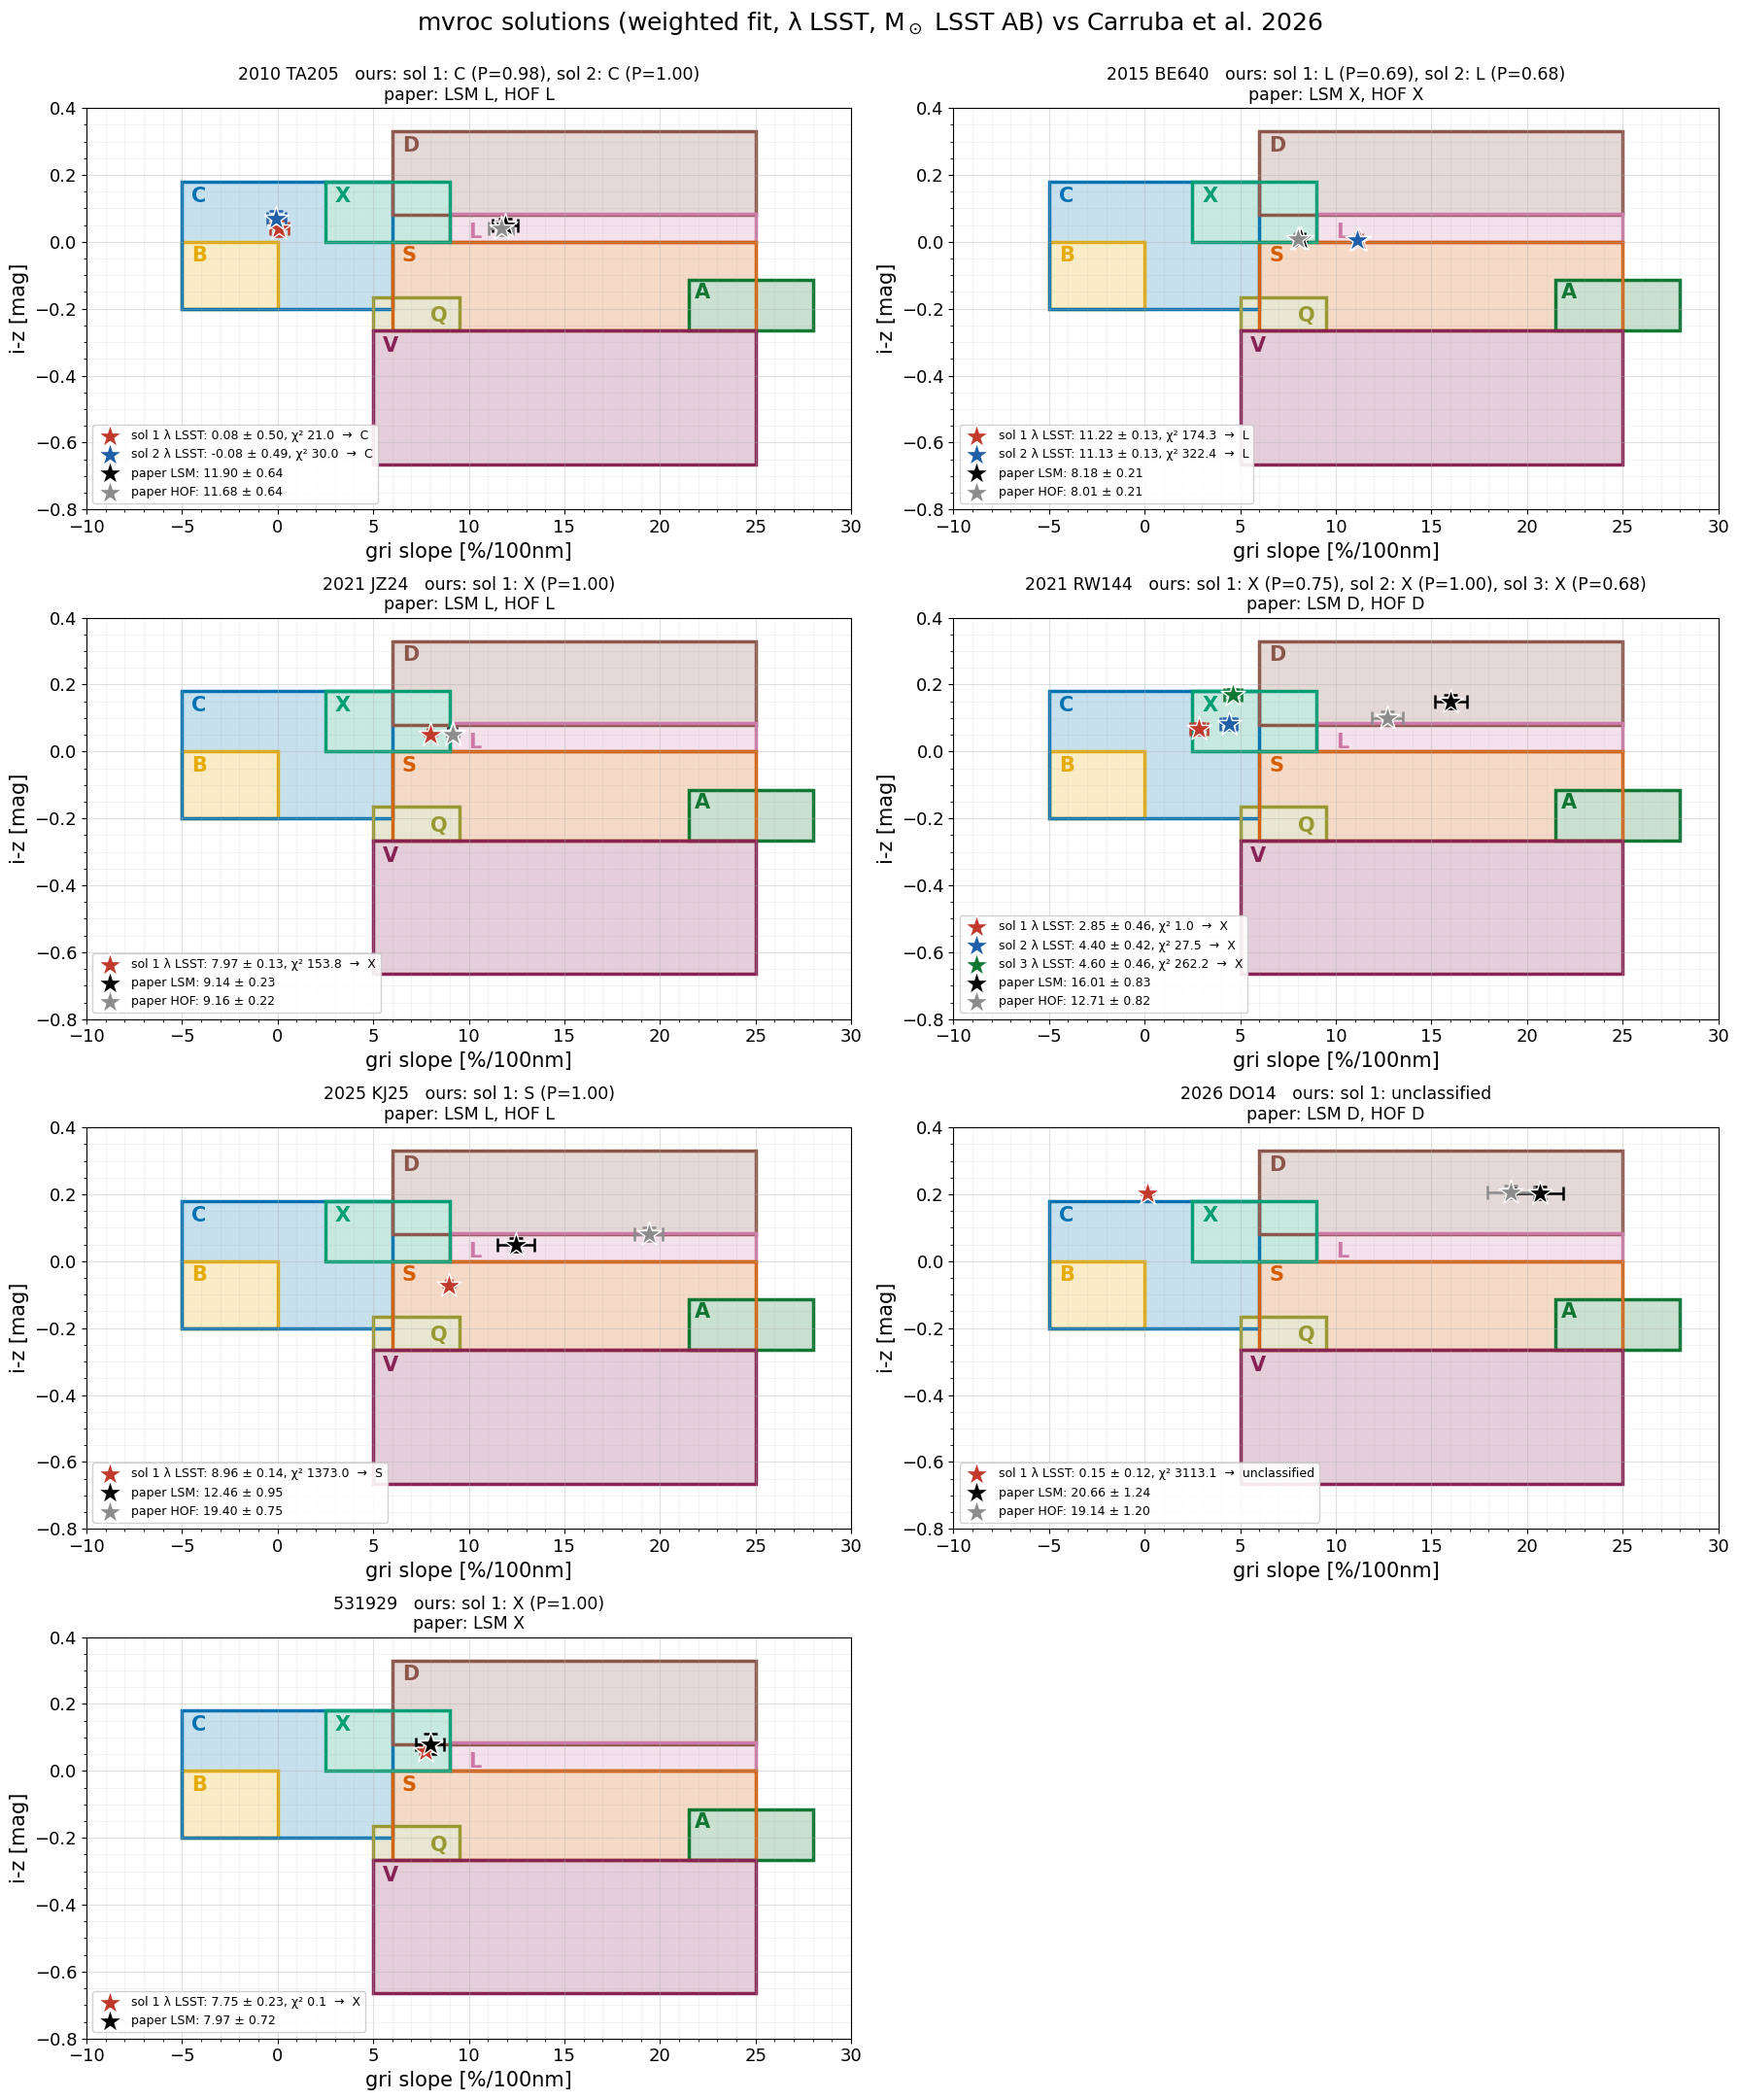

In [14]:
names_cf = list(dict.fromkeys(mv_paper_cf['designation']))
nrows = int(np.ceil(len(names_cf) / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(18, 5.5 * nrows), squeeze=False)
for ax, name in zip(axes.flat, names_cf):
    g = mv_paper_cf[mv_paper_cf['designation'] == name]
    r0 = g.iloc[0]
    points = []
    for k, (_, r) in enumerate(g.iterrows()):
        points.append(dict(label=f"sol {r['solution_id']} λ LSST: {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f},"
                                 f" χ² {r['chi2']:.1f}  →  {r['taxonomy_lsst']}",
                           slope=r['slope_lsst'], slope_err=r['slope_lsst_err'], iz=r['i_z'], iz_err=r['i_z_err'],
                           color=SOL_COLORS[k % len(SOL_COLORS)]))
    points.append(dict(label=f"paper LSM: {r0['gri_slope_LSM']:.2f} ± {r0['gri_slope_LSM_err']:.2f}",
                       slope=r0['gri_slope_LSM'], slope_err=r0['gri_slope_LSM_err'],
                       iz=r0['i_z_LSM'], iz_err=r0['i_z_LSM_err'], color='#000000'))
    points.append(dict(label=f"paper HOF: {r0['gri_slope_HOF']:.2f} ± {r0['gri_slope_HOF_err']:.2f}",
                       slope=r0['gri_slope_HOF'], slope_err=r0['gri_slope_HOF_err'],
                       iz=r0['i_z_HOF'], iz_err=r0['i_z_HOF_err'], color='#8c8c8c'))
    points = [p for p in points if np.isfinite(p['slope']) and np.isfinite(p['iz'])]
    tx.plot_taxonomy(points, ax=ax)
    ours_lbl = ', '.join(f"sol {r['solution_id']}: {class_label(r, 'lsst')}" for _, r in g.iterrows())
    paper_lbl = f"LSM {r0['taxonomy_LSM']}" + (f", HOF {r0['taxonomy_HOF']}" if pd.notna(r0['taxonomy_HOF']) else '')
    ax.set_title(f"{name}   ours: {ours_lbl}\npaper: {paper_lbl}", fontsize=12.5)
    ax.legend(loc='lower left', fontsize=9, framealpha=0.9)
for ax in axes.flat[len(names_cf):]:
    ax.axis('off')
fig.suptitle('mvroc solutions (weighted fit, λ LSST, M$_\\odot$ LSST AB) vs Carruba et al. 2026', fontsize=18)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(os.path.join(FIG_DIR_MV_CF, '_carruba_comparison_mvroc.png'), dpi=150)
plt.show()

## 3. Mean H per band (`H_promedio_por_objeto.parquet`): weighted linear fit of the reflectances, LSST

For every object with g, r, i and z:

1. Reflectances from the mean H of each band, LSST AB solar magnitudes, normalised to g
   (`tx.gri_reflectances`): $R_f = 10^{-0.4[(H_f - H_g) - (M_{f,\odot} - M_{g,\odot})]}$.
2. Reflectance errors by error propagation from the H error of the same band (`H_*_err_scaled`):
   $\sigma_{R_f} = 0.4\ln 10\, R_f\, \sigma_{H_f}$. $H_g$ only sets the normalisation, so the three points are
   independent and $R_g = 1 \pm 0.4\ln10\,\sigma_{H_g}$.
3. Straight line $R(\lambda) = a + b\lambda$ at the LSST wavelengths with `scipy.optimize.curve_fit`
   (`tx.gri_slope_fit`), `sigma` = reflectance errors, `absolute_sigma=True`; the wavelengths are taken as exact.
   The slope and intercept errors come from the fit covariance; gri slope $= 10^4 b$ [%/100nm].
4. $\chi^2 = \sum_k [(R_k - a - b\lambda_k)/\sigma_{R_k}]^2$ with 3 − 2 = 1 degree of freedom.

i−z = $H_i - H_z$ as before. Figures and tables go to `figures/taxonomy_H_promedio_curvefit_lsst/`
(the previous unweighted results stay in `figures/taxonomy_H_promedio_fit_lsst/`).

In [15]:
HPROM = 'data/H_promedio_por_objeto.parquet'
FIG_DIR_HP = 'figures/taxonomy_jpl'
os.makedirs(FIG_DIR_HP, exist_ok=True)

hp = pd.read_parquet(HPROM)
hp4 = hp[hp[[f'H_L{b}_mean' for b in 'griz']].notna().all(axis=1)].reset_index(drop=True)

hp_tax = pd.DataFrame({'provid': hp4['object_id'].astype(str), 'solution_id': 1})
for b in 'griz':
    hp_tax[f'H_{b}'] = hp4[f'H_L{b}_mean']
    hp_tax[f'H_{b}_err'] = hp4[f'H_L{b}_err_scaled']
    hp_tax[f'N_{b}'] = hp4[f'N_L{b}']
for c1, c2 in [('g', 'r'), ('r', 'i'), ('i', 'z')]:
    hp_tax[f'{c1}-{c2}'] = hp_tax[f'H_{c1}'] - hp_tax[f'H_{c2}']
    hp_tax[f'{c1}-{c2}_err'] = np.hypot(hp_tax[f'H_{c1}_err'], hp_tax[f'H_{c2}_err'])

# 1-2. reflectances and their errors
R = tx.gri_reflectances(hp_tax['H_g'], hp_tax['H_r'], hp_tax['H_i'],
                        hp_tax['H_g_err'], hp_tax['H_r_err'], hp_tax['H_i_err'], m_sun=tx.M_SUN_LSST)
hp_tax = pd.concat([hp_tax, R], axis=1)

# 3-4. weighted fit, one per object
fit = tx.gri_slope_fit(R[['R_g', 'R_r', 'R_i']], R[['R_g_err', 'R_r_err', 'R_i_err']], lam=tx.LAM_LSST)
hp_tax['slope_lsst'] = fit['slope']
hp_tax['slope_lsst_err'] = fit['slope_err']
hp_tax['intercept'] = fit['intercept']
hp_tax['intercept_err'] = fit['intercept_err']
hp_tax['cov_ab'] = fit['cov_ab']
hp_tax['chi2'] = fit['chi2']
hp_tax['ndof'] = fit['ndof']
hp_tax['p_value'] = fit['p_value']
hp_tax['i_z'] = hp_tax['i-z']
hp_tax['i_z_err'] = hp_tax['i-z_err']
hp_tax['slope_unweighted'] = tx.gri_slope_fit_colors(hp_tax['g-r'], hp_tax['r-i'])   # section 8 before, reference

res = tx.classify_catalogue(hp_tax['slope_lsst'], hp_tax['i_z'], hp_tax['slope_lsst_err'], hp_tax['i_z_err'])
hp_tax['taxonomy_lsst'] = res['taxonomy']
hp_tax['p_class_lsst'] = res['p_class']
hp_tax['candidates_lsst'] = res['candidates']

print(f'{len(hp)} objects in {HPROM}; with g, r, i and z: {len(hp_tax)}')
print(hp_tax['taxonomy_lsst'].value_counts().to_string())
d = hp_tax['slope_lsst'] - hp_tax['slope_unweighted']
print(f"\nweighted - unweighted slope: median {d.median():.2f}, 16-84% [{d.quantile(.16):.2f}, {d.quantile(.84):.2f}]")
print(f"chi2 (1 dof): median {hp_tax['chi2'].median():.2f}; chi2 > 3.84 (p < 0.05): "
      f"{(hp_tax['chi2'] > 3.84).mean():.0%} of the objects")

fit_cols = ['provid', 'solution_id', 'R_g', 'R_g_err', 'R_r', 'R_r_err', 'R_i', 'R_i_err',
            'slope_lsst', 'slope_lsst_err', 'intercept', 'intercept_err', 'cov_ab', 'chi2', 'ndof', 'p_value',
            'i_z', 'i_z_err', 'taxonomy_lsst', 'p_class_lsst', 'candidates_lsst']
hp_fit_params = hp_tax[fit_cols]
hp_tax.to_csv(os.path.join(FIG_DIR_HP, 'taxonomy_jpl.csv'), index=False)
hp_fit_params.to_csv(os.path.join(FIG_DIR_HP, 'fit_jpl.csv'), index=False)
hp_fit_params.head(10).round(4)

9432 objects in data/H_promedio_por_objeto.parquet; with g, r, i and z: 3168
taxonomy_lsst
indeterminate    875
unclassified     541
S                512
C                469
X                421
D                164
L                103
V                 44
B                 37
Q                  1
A                  1

weighted - unweighted slope: median 0.05, 16-84% [-0.59, 1.59]
chi2 (1 dof): median 4.54; chi2 > 3.84 (p < 0.05): 53% of the objects


,provid,solution_id,R_g,R_g_err,R_r,R_r_err,R_i,R_i_err,slope_lsst,slope_lsst_err,intercept,intercept_err,cov_ab,chi2,ndof,i_z,i_z_err,taxonomy_lsst,p_class_lsst,candidates_lsst
0,2016 GC22,1,1.0,0.0056,1.1243,0.0098,1.1689,0.0054,6.1383,0.2841,0.7100,0.0180,-0.0050,12.5298,1,-0.0547,0.0133,S,0.6427,S 0.64 / C 0.36
1,2026 DD30,1,1.0,0.0097,1.0933,0.0197,1.0623,0.0094,2.2618,0.4891,0.8977,0.0311,-0.0149,8.6795,1,0.0388,0.0153,C,0.6687,C 0.67 / X 0.33
2,2026 DB30,1,1.0,0.0052,1.0452,0.0055,1.0277,0.0033,0.7867,0.2190,0.9726,0.0148,-0.0032,24.3514,1,0.0654,0.0082,C,1.0000,C 1.00
3,2026 DK30,1,1.0,0.0059,1.0961,0.0059,1.1832,0.0036,6.6395,0.2445,0.6816,0.0166,-0.0040,0.0835,1,0.0054,0.0102,X,0.6459,X 0.65 / S 0.34
4,2026 DZ29,1,1.0,0.0120,1.0349,0.0196,1.0713,0.0081,2.5952,0.5228,0.8750,0.0353,-0.0182,0.0065,1,0.0216,0.0256,indeterminate,0.5596,C 0.56 / X 0.44
5,2026 DY30,1,1.0,0.0107,1.1864,0.0124,1.1036,0.0091,3.4309,0.5094,0.8721,0.0330,-0.0165,87.7964,1,0.1087,0.0139,X,0.9514,X 0.95
6,2026 DQ29,1,1.0,0.0033,0.9899,0.0041,0.9650,0.0022,-1.3076,0.1428,1.0648,0.0096,-0.0014,2.9258,1,0.0579,0.0062,C,1.0000,C 1.00
7,2026 DA30,1,1.0,0.0073,1.0893,0.0056,1.1831,0.0049,6.7008,0.3125,0.6754,0.0207,-0.0064,0.4621,1,0.0298,0.0119,X,0.9712,X 0.97
8,2026 DO29,1,1.0,0.0061,1.0958,0.0054,1.1636,0.0039,5.8364,0.2579,0.7246,0.0173,-0.0044,3.2932,1,0.0669,0.0107,X,1.0000,X 1.00
9,2026 DG29,1,1.0,0.0203,1.0729,0.0128,1.0389,0.0127,0.6717,0.8332,1.0026,0.0552,-0.0455,9.2417,1,-0.0068,0.0169,C,0.8544,C 0.85 / B 0.14


### 3.1 Overview (weighted fit, LSST)

All classified objects (box letter or indeterminate); objects outside every box are not drawn.

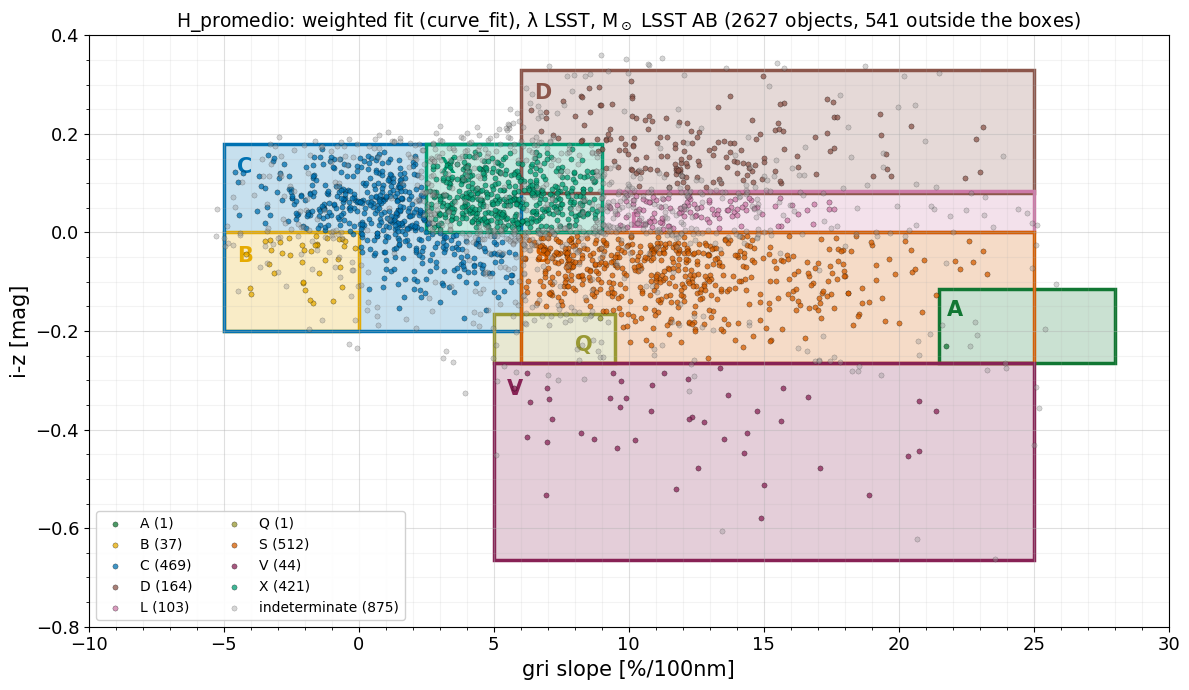

In [16]:
sel_hp = hp_tax[hp_tax['taxonomy_lsst'] != tx.UNCLASSIFIED]
fig, ax = plt.subplots(figsize=(12, 7))
tx.plot_taxonomy([], ax=ax, legend=False)
order = sorted(sel_hp['taxonomy_lsst'].unique(), key=lambda c: (c == tx.INDETERMINATE, c))
for label in order:
    g = sel_hp[sel_hp['taxonomy_lsst'] == label]
    ax.scatter(g['slope_lsst'], g['i_z'], s=14, color=colors[label], edgecolors='k', linewidths=0.25,
               alpha=0.75 if label != tx.INDETERMINATE else 0.4, label=f'{label} ({len(g)})', zorder=4)
n_out = (hp_tax['taxonomy_lsst'] == tx.UNCLASSIFIED).sum()
ax.set_title(f'H_promedio: weighted fit (curve_fit), λ LSST, M$_\\odot$ LSST AB '
             f'({len(sel_hp)} objects, {n_out} outside the boxes)', fontsize=13.5)
ax.legend(loc='lower left', fontsize=10, framealpha=0.9, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR_HP, '_overview_taxonomy.png'), dpi=150)
plt.show()

### Fit quality

Left: χ² of every fit against the χ² distribution with 1 degree of freedom. Right: slope error vs slope.

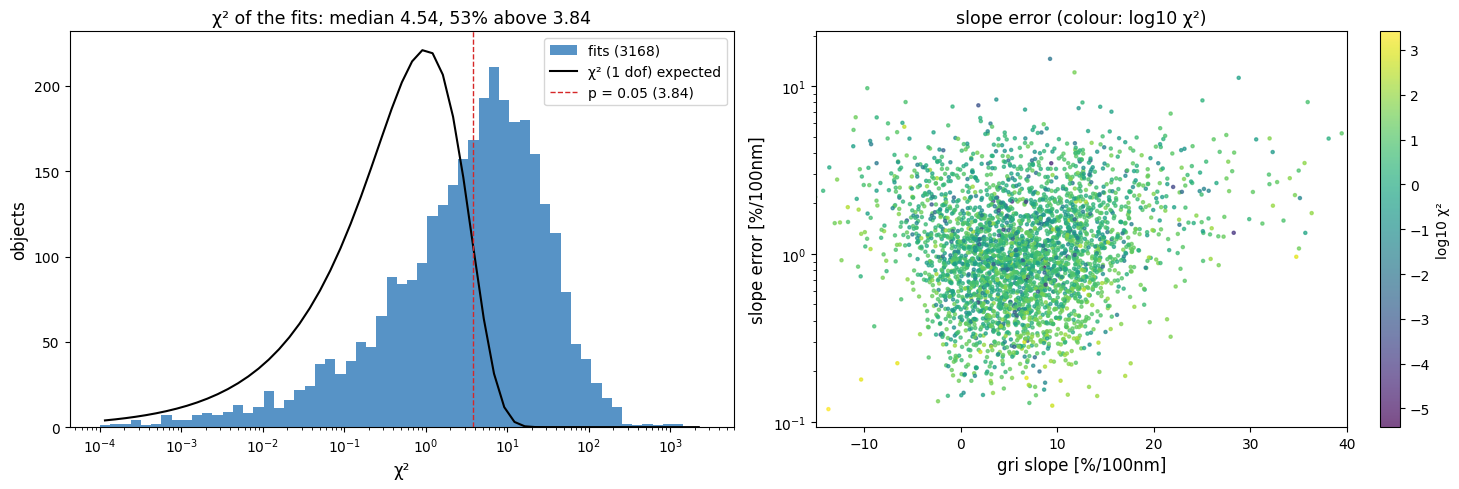

In [17]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
c2 = hp_tax['chi2'].dropna()
bins = np.logspace(np.log10(max(c2.min(), 1e-4)), np.log10(c2.max()), 60)
ax.hist(c2, bins=bins, color='#1f6fb4', alpha=0.75, label=f'fits ({len(c2)})')
centers = np.sqrt(bins[1:] * bins[:-1])
ax.plot(centers, len(c2) * np.diff(stats.chi2.cdf(bins, 1)), 'k-', lw=1.5, label='χ² (1 dof) expected')
ax.axvline(3.84, color='#d62728', ls='--', lw=1, label='p = 0.05 (3.84)')
ax.set_xscale('log')
ax.set_xlabel('χ²', fontsize=12)
ax.set_ylabel('objects', fontsize=12)
ax.set_title(f"χ² of the fits: median {c2.median():.2f}, {(c2 > 3.84).mean():.0%} above 3.84", fontsize=12.5)
ax.legend(fontsize=10)

ax = axes[1]
ax.scatter(hp_tax['slope_lsst'], hp_tax['slope_lsst_err'], s=5, c=np.log10(hp_tax['chi2']), cmap='viridis', alpha=0.7)
ax.set_yscale('log')
ax.set_xlim(-15, 40)
ax.set_xlabel('gri slope [%/100nm]', fontsize=12)
ax.set_ylabel('slope error [%/100nm]', fontsize=12)
ax.set_title('slope error (colour: log10 χ²)', fontsize=12.5)
fig.colorbar(ax.collections[0], ax=ax, label='log10 χ²')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR_HP, '_fit_chi2.png'), dpi=150)
plt.show()

### 3.2 Comparison with Carruba et al. (2026)

`object_id` is matched against the paper's `designation` (provisional designation or number).

In [18]:
hp_paper = carruba_objects[paper_cols].merge(hp_tax, left_on='designation', right_on='provid')
hp_paper['agree'] = hp_paper.apply(agree, axis=1)
in_hp = carruba_objects['designation'].isin(hp['object_id'].astype(str))
print(f'{in_hp.sum()} of {len(carruba_objects)} paper objects are in {HPROM}; {len(hp_paper)} have g, r, i and z')
print(hp_paper['agree'].value_counts().to_string())
hp_paper.to_csv(os.path.join(FIG_DIR_HP, 'carruba_comparison_jpl.csv'), index=False)
hp_paper[['designation', 'g-r', 'r-i', 'i-z', 'slope_lsst', 'slope_lsst_err', 'gri_slope_LSM', 'gri_slope_HOF',
          'i_z_LSM', 'taxonomy_lsst', 'candidates_lsst', 'taxonomy_LSM', 'taxonomy_HOF', 'taxonomy_final',
          'agree']].round(3)

35 of 36 paper objects are in data/H_promedio_por_objeto.parquet; 30 have g, r, i and z
agree
no               14
yes               7
-                 6
in candidates     3


,designation,g-r,r-i,i-z,slope_lsst,slope_lsst_err,gri_slope_LSM,gri_slope_HOF,i_z_LSM,taxonomy_lsst,candidates_lsst,taxonomy_LSM,taxonomy_HOF,taxonomy_final,agree
0,3021,0.304,0.204,-0.013,-0.638,0.503,12.59,NaN,NaN,B,B 0.66 / C 0.34,NaN,NaN,NaN,-
1,92048,0.673,-0.124,0.069,-2.488,0.759,10.15,NaN,0.220,C,C 1.00,D,NaN,D,no
2,175194,0.515,0.198,-0.002,6.655,0.994,12.03,NaN,NaN,indeterminate,X 0.47 / S 0.38 / C 0.14,NaN,NaN,NaN,-
3,415837,0.634,0.416,-0.060,22.761,0.816,6.01,NaN,-0.100,S,S 1.00,S,NaN,S,yes
4,441953,0.529,0.368,0.066,14.516,0.627,0.86,NaN,NaN,L,L 0.77 / D 0.22,NaN,NaN,NaN,-
5,527964,0.606,0.394,0.129,19.578,0.392,7.40,NaN,0.160,D,D 1.00,D,NaN,D,yes
6,531929,0.495,0.272,0.089,8.309,0.299,7.97,NaN,0.080,X,X 0.96,X,NaN,X,yes
7,614376,0.568,0.209,-0.044,9.573,0.384,10.05,NaN,NaN,S,S 0.97,NaN,NaN,NaN,-
8,618498,0.631,0.233,-0.094,13.036,0.421,8.10,NaN,-0.090,S,S 1.00,S,NaN,S,yes
9,659448,0.654,0.341,-0.025,19.002,0.498,10.91,NaN,NaN,S,S 0.90 / L 0.10,NaN,NaN,NaN,-


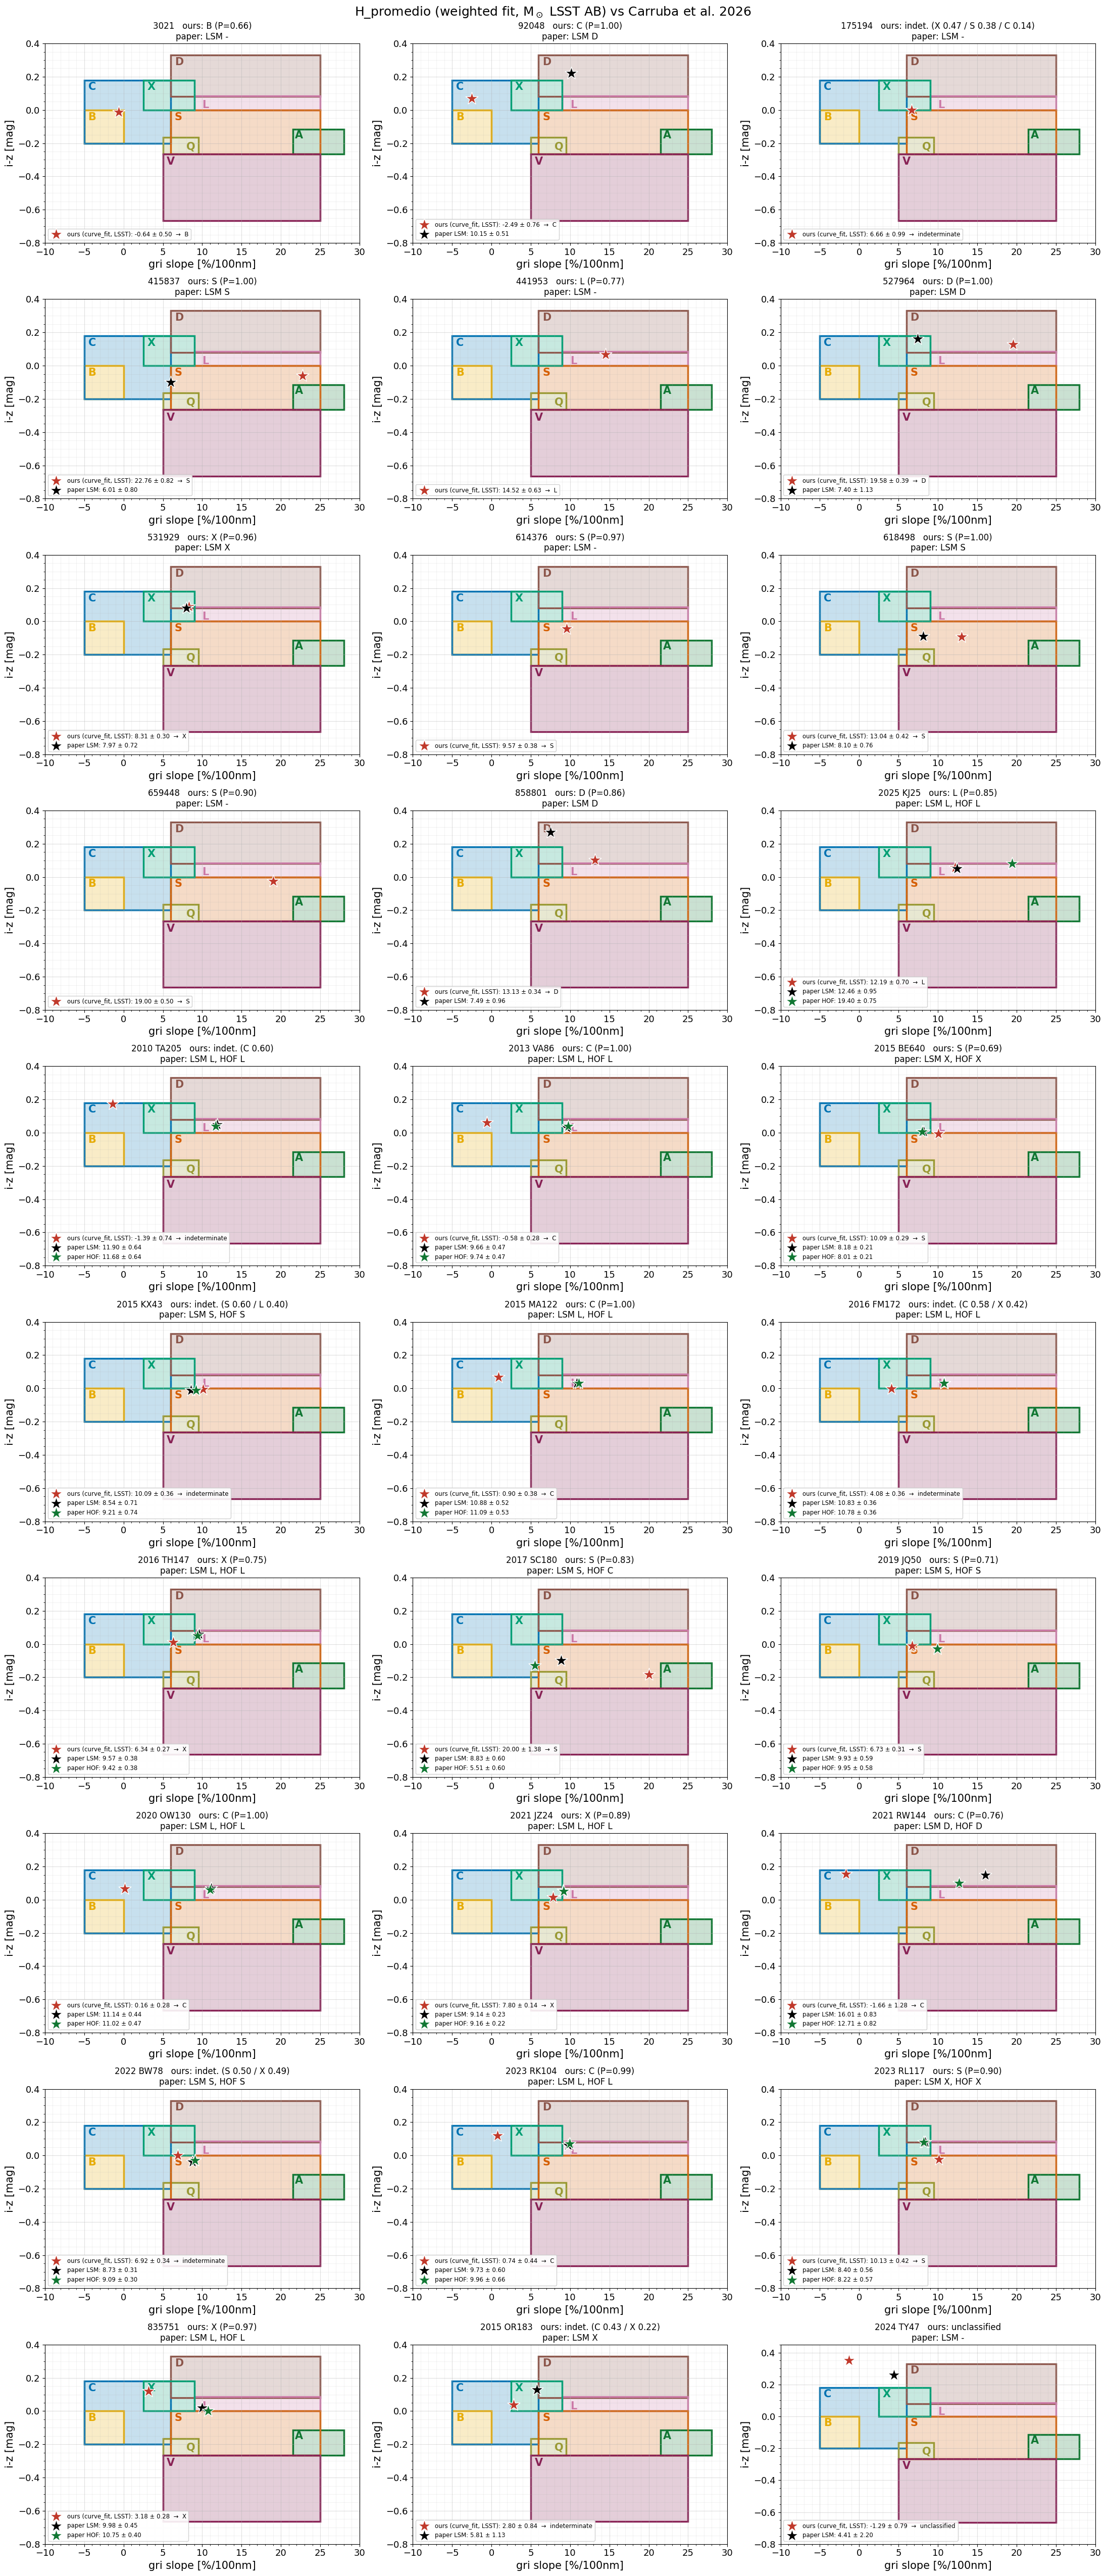

In [19]:
names_hp = list(hp_paper['designation'])
ncols = 3
nrows = int(np.ceil(len(names_hp) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(22, 5.2 * nrows), squeeze=False)
for ax, (_, r) in zip(axes.flat, hp_paper.iterrows()):
    points = [
        dict(label=f"ours (curve_fit, LSST): {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f}  →  {r['taxonomy_lsst']}",
             slope=r['slope_lsst'], iz=r['i_z'], color='#C0392B'),
        dict(label=f"paper LSM: {r['gri_slope_LSM']:.2f} ± {r['gri_slope_LSM_err']:.2f}",
             slope=r['gri_slope_LSM'], iz=r['i_z_LSM'],
             color='#000000'),
        dict(label=f"paper HOF: {r['gri_slope_HOF']:.2f} ± {r['gri_slope_HOF_err']:.2f}",
             slope=r['gri_slope_HOF'], iz=r['i_z_HOF'],
             color='#117733'),
    ]
    # section 3: no error bars
    points = [p for p in points if np.isfinite(p['slope']) and np.isfinite(p['iz'])]
    tx.plot_taxonomy(points, ax=ax)
    paper_lbl = (f"LSM {r['taxonomy_LSM']}" if pd.notna(r['taxonomy_LSM']) else 'LSM -') + \
        (f", HOF {r['taxonomy_HOF']}" if pd.notna(r['taxonomy_HOF']) else '')
    ax.set_title(f"{r['designation']}   ours: {class_label(r, 'lsst')}\npaper: {paper_lbl}", fontsize=12)
    ax.legend(loc='lower left', fontsize=8.5, framealpha=0.9)
for ax in axes.flat[len(names_hp):]:
    ax.axis('off')
fig.suptitle('H_promedio (weighted fit, M$_\\odot$ LSST AB) vs Carruba et al. 2026', fontsize=18)
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(os.path.join(FIG_DIR_HP, '_carruba_comparison_jpl.png'), dpi=110)
plt.show()

### 3.3 Selected objects

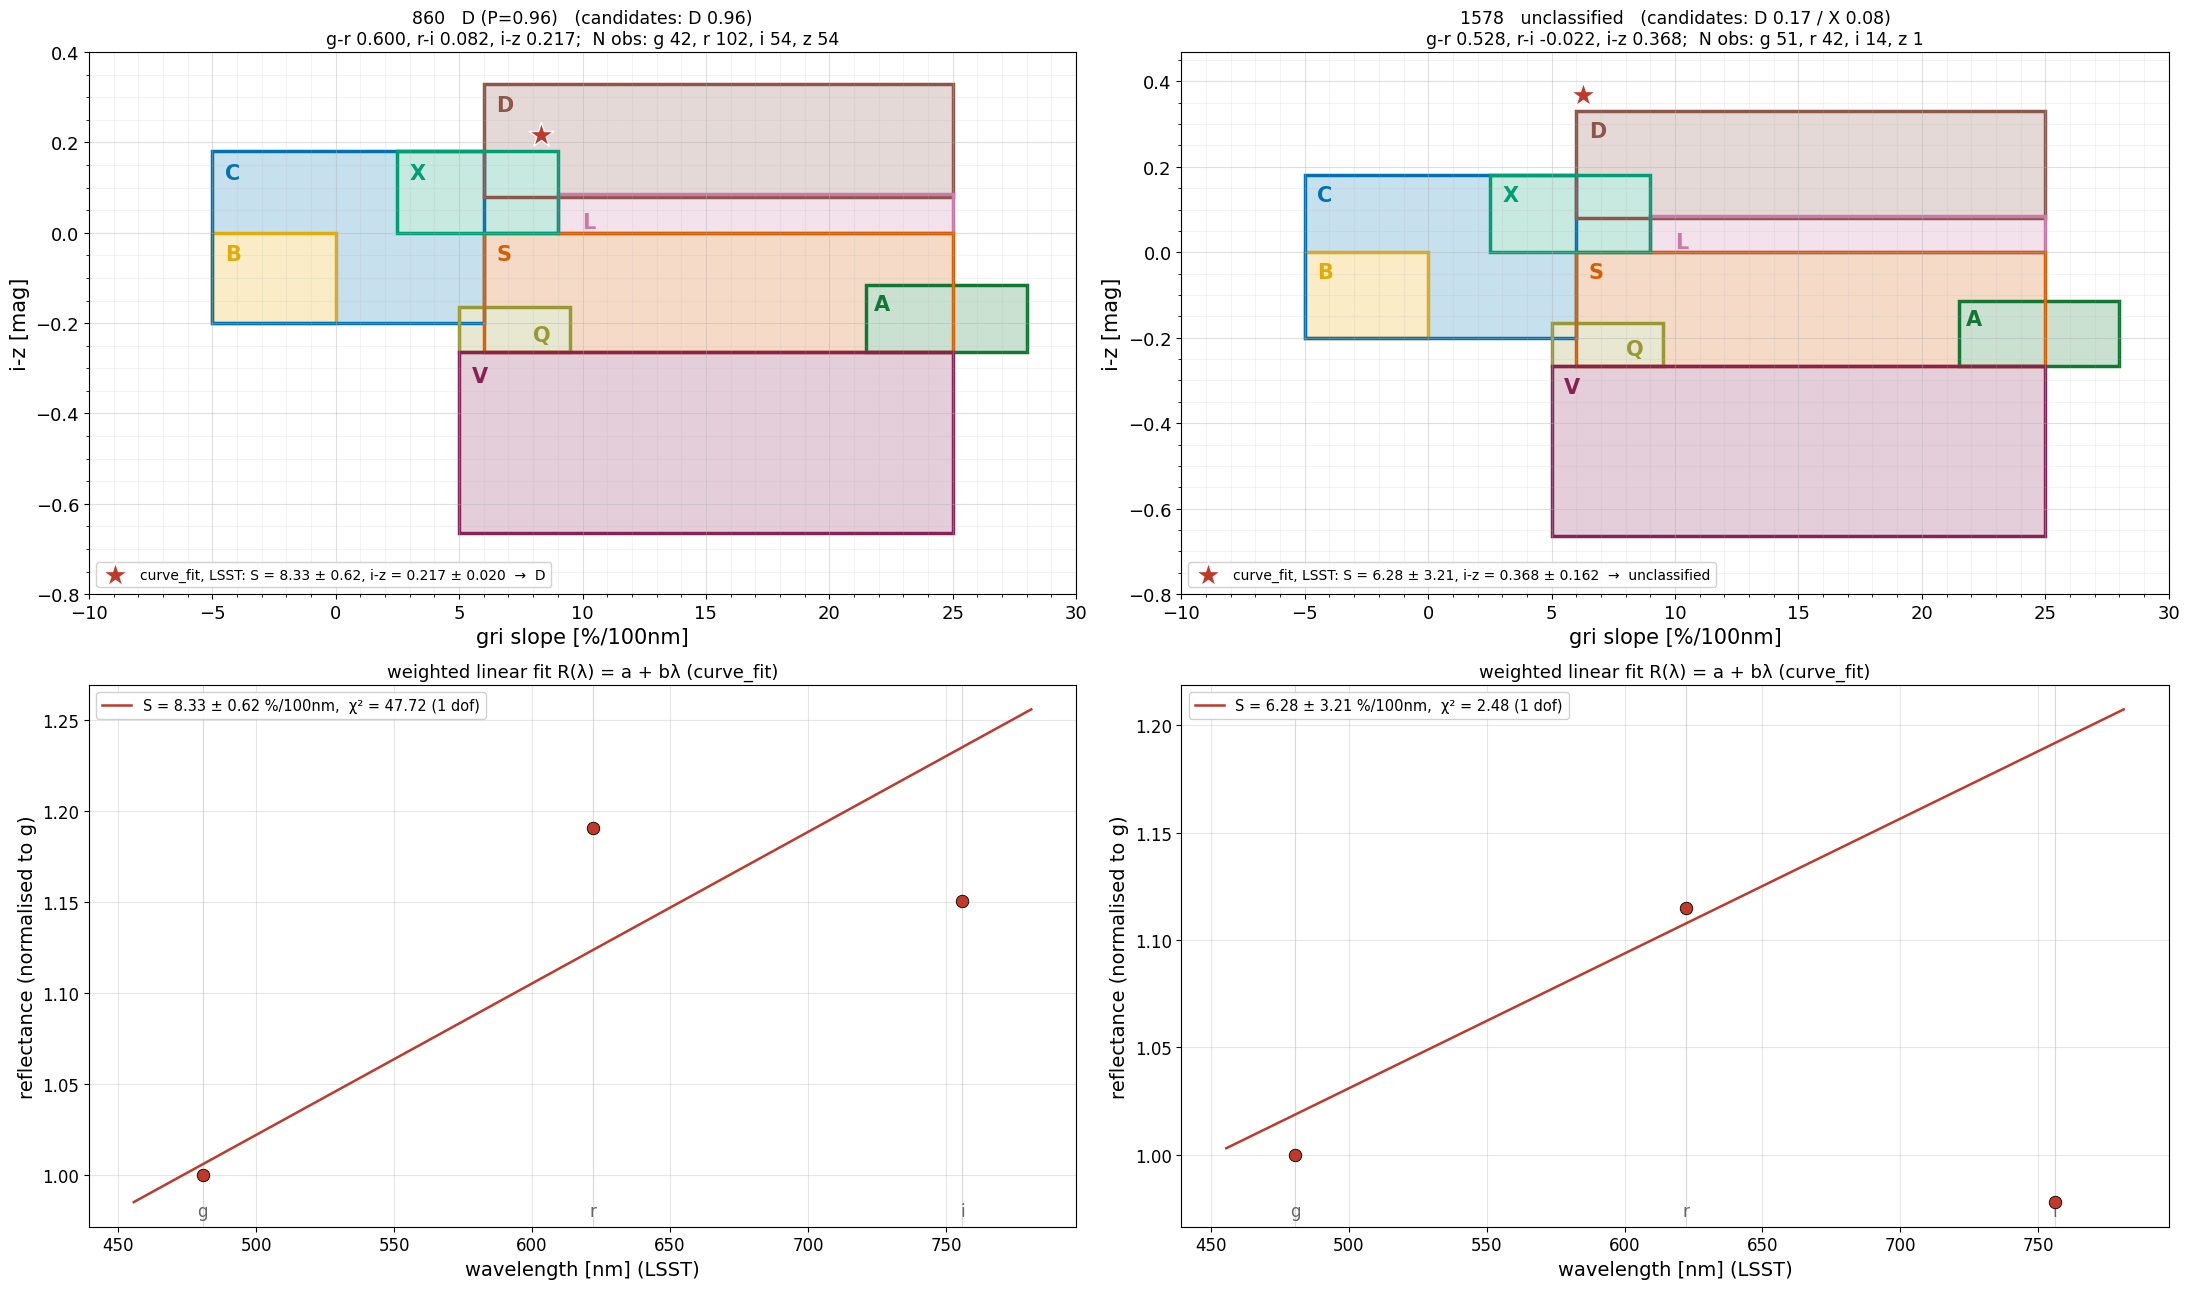

In [20]:
def plot_hp_objects(ids, fname=None):
    # one column per object: taxonomy on top, reflectances and their weighted linear fit below (no error bars)
    fig, axes = plt.subplots(2, len(ids), figsize=(11 * len(ids), 13), squeeze=False)
    lam = np.array([tx.LAM_LSST[b] for b in 'gri'])
    lam_line = np.linspace(lam.min() - 25, lam.max() + 25, 50)
    for k, oid in enumerate(ids):
        ax, axf = axes[0, k], axes[1, k]
        r = hp_tax[hp_tax['provid'] == str(oid)].iloc[0]
        nobs = ', '.join(f"{b} {r[f'N_{b}']}" for b in 'griz')
        point = dict(label=f"curve_fit, LSST: S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f}, "
                           f"i-z = {r['i_z']:.3f} ± {r['i_z_err']:.3f}  →  {r['taxonomy_lsst']}",
                     slope=r['slope_lsst'], iz=r['i_z'], color='#C0392B')
        tx.plot_taxonomy([point], ax=ax)
        ax.set_title(f"{oid}   {class_label(r, 'lsst')}   (candidates: {r['candidates_lsst'] or '-'})\n"
                     f"g-r {r['g-r']:.3f}, r-i {r['r-i']:.3f}, i-z {r['i-z']:.3f};  N obs: {nobs}", fontsize=12.5)
        ax.legend(loc='lower left', fontsize=10, framealpha=0.9)

        R = np.array([r[f'R_{b}'] for b in 'gri'])
        axf.plot(lam, R, 'o', ms=9, color='#C0392B', mec='k', mew=0.6, zorder=5)
        axf.plot(lam_line, r['intercept'] + r['slope_lsst'] / 1e4 * lam_line, '-', color='#C0392B', lw=1.8,
                 label=f"S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f} %/100nm,  "
                       f"χ² = {r['chi2']:.2f} ({int(r['ndof'])} dof), p = {r['p_value']:.2g}")
        for b, l in zip('gri', lam):
            axf.axvline(l, color='0.85', lw=0.8, zorder=0)
            axf.text(l, 0.02, b, transform=axf.get_xaxis_transform(), ha='center', fontsize=12, color='0.4')
        axf.set_xlabel('wavelength [nm] (LSST)', fontsize=14)
        axf.set_ylabel('reflectance (normalised to g)', fontsize=14)
        axf.tick_params(labelsize=12)
        axf.grid(alpha=0.3)
        axf.legend(loc='upper left', fontsize=10.5, framealpha=0.9)
        axf.set_title('weighted linear fit R(λ) = a + bλ (curve_fit)', fontsize=13)
    fig.tight_layout()
    if fname:
        fig.savefig(os.path.join(FIG_DIR_HP, fname), dpi=150)
    return fig, axes


fig, axes = plot_hp_objects(['860', '1578'], fname='860_1578_taxonomy.png')
plt.show()